# Question Answering over a PDF with RAG
A retrieval-augmented generation (RAG) pipeline built with LlamaIndex that answers questions about one magazine-style PDF: *WebMD Real Stories: Chronic Migraine* (Winter 2025).

Sections 1 to 6 set up a provided LlamaIndex RAG template (loading, indexing, retrievers, evaluation). Steps 1 to 5 build on it:
1. Test set and baseline, including a bug fix in the auto-merging retriever
2. A layout-aware ingestion pipeline and chunking experiments
3. OCR for content that exists only as images
4. Hybrid retrieval (vector + BM25)
5. Re-ranking, section headers and a grounded prompt


In [1]:
%pip install python-dotenv huggingface-hub "llama-index==0.12.17" transformers sentence-transformers "llama-index-llms-huggingface==0.4.2" "llama-index-embeddings-huggingface==0.5.1" pdfplumber "llama-index-llms-openrouter==0.3.1" "llama-index-retrievers-bm25==0.5.2" tabula-py  jpype1 pystemmer

Note: you may need to restart the kernel to use updated packages.


**Note:** After installation finishes, restart the kernel, then continue from Section 1.

## 1. Setup & Configuration
Load the OpenRouter API key, then set up the answer LLM (`mistralai/mistral-nemo`), the judge LLM (`deepseek/deepseek-v4-flash-0731`) and the embedding model (`all-MiniLM-L6-v2`).

**API key:** copy `.env.example` to `.env` and set `OPENROUTER_API_KEY`. On Google Colab, a Colab secret with the same name also works.

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # Suppresses TensorFlow warnings
from dotenv import load_dotenv
import Stemmer
import nest_asyncio
import tabula
import pandas as pd
from llama_index.core import Document
from llama_index.core import (SimpleDirectoryReader, VectorStoreIndex, Settings)
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
import asyncio
import matplotlib.pyplot as plt   
import numpy as np

# ── 1. Robust API Key Loading (Secrets -> .env Fallback) ─────────────────────
api_key = None
auth_source = None

# Attempt Option A: Google Colab Secrets (Recommended)
try:
    from google.colab import userdata
    api_key = userdata.get("OPENROUTER_API_KEY")
    if api_key:
        auth_source = "Colab Secrets (🔑)"
except Exception:
    pass

# Attempt Option B: .env file fallback (or local environment variable)
if not api_key:
    load_dotenv(override=True)
    api_key = os.getenv("OPENROUTER_API_KEY")
    if api_key and not api_key.startswith("YOUR_"):
        auth_source = ".env file"

# Verify credential resolution
if api_key and not api_key.startswith("YOUR_"):
    print(f"✅ OpenRouter API key loaded from {auth_source}")
else:
    raise ValueError(
        "❌ Missing OpenRouter API Key!\n\n"
        "Please provide your key using ONE of these methods:\n"
        "  • Option A (Recommended): Add 'OPENROUTER_API_KEY' to Google Colab Secrets (🔑 in the left sidebar).\n"
        "  • Option B: Upload your '.env' file containing 'OPENROUTER_API_KEY=sk-or-v1-...' to the Colab files panel."
    )


# Answer LLM and judge LLM, the same for every experiment
llm = OpenRouter(api_key=api_key, model="mistralai/mistral-nemo", max_tokens=512, context_window=4096)
Judge_llm = OpenRouter(api_key=api_key, model="deepseek/deepseek-v4-flash-0731", max_tokens=512, context_window=4096)
Settings.llm = llm

# Apply nest_asyncio to fix event loop issues in Jupyter
nest_asyncio.apply()

# Set up embedding model
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)


./.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2350: UnsupportedFieldAttributeWarning: The 'validate_default' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'validate_default' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(


./.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ OpenRouter API key loaded from .env file


In [3]:
# I check the API key once; cells that need the LLM skip if it fails
def check_llm():
    try:
        llm.complete("Reply with the single word OK.")
        return True
    except Exception as e:
        print(f"LLM unavailable ({type(e).__name__}): {str(e)[:160]}")
        return False

LLM_AVAILABLE = check_llm()
print("LLM_AVAILABLE =", LLM_AVAILABLE)


LLM_AVAILABLE = True


## 2. Document Loading & Preprocessing
Here, we load the WebMD document from a PDF file and process it for retrieval.

Key Steps:
- Read the WebMD PDF and extract its textual content.
- Extract tabular data from the PDF using `tabula`.
- Convert the extracted table data into text format.
- Combine the extracted text and tables into a unified document.
- Define an ingestion pipeline to preprocess text by splitting it into manageable chunks and applying embeddings.


In [4]:
# Load the WebMD PDF
pdf_path = "./WebMD.pdf"   
documents = SimpleDirectoryReader(input_files=[pdf_path]).load_data()

# Convert table data into an additional Document
tables = tabula.read_pdf(pdf_path, pages="all", silent=True, force_subprocess=True)   # Java runs in its own process (it crashed Python on exit otherwise)
table_docs = [df.to_markdown(index=False) for df in tables]
all_tables_text = "\n\n".join(table_docs)
document_from_tables = Document(text=all_tables_text)

# Combine original + table doc
documents = documents + [document_from_tables]
# I fixed the ids so my cached dataset stays valid
for i, d in enumerate(documents):
    d.id_ = f"doc{i}"

# Create the pipeline with transformations
from llama_index.core.node_parser import SentenceSplitter
from llama_index.core.ingestion import IngestionPipeline

pipeline = IngestionPipeline(transformations=[SentenceSplitter(chunk_size=256, chunk_overlap=0, id_func=lambda i, doc: f"{doc.doc_id}_{i}"), embed_model])

# Run the pipeline
nodes = pipeline.run(documents=documents)
print(f"Number of nodes extracted: {len(nodes)}")

Ignoring wrong pointing object 13 0 (offset 0)


Ignoring wrong pointing object 16 0 (offset 0)


Ignoring wrong pointing object 18 0 (offset 0)


Ignoring wrong pointing object 20 0 (offset 0)


Ignoring wrong pointing object 22 0 (offset 0)


Ignoring wrong pointing object 24 0 (offset 0)


... (18 outputs left out)

Ignoring wrong pointing object 1918 0 (offset 0)


Ignoring wrong pointing object 4963 0 (offset 0)


Ignoring wrong pointing object 4965 0 (offset 0)


Number of nodes extracted: 74


## 3. Indexing & Retrieval
Once the document is processed, we create multiple retrievers for efficient information retrieval.

Key Steps:
- Build a `VectorStoreIndex` from the preprocessed document chunks.
- Implement different retrieval methods:
  - **Base Retriever:** Retrieves the 3 most similar chunks.
  - **AutoMerging Retriever:** Aggregates multiple related chunks before returning results.
  - **BM25 Retriever:** Uses term frequency-based ranking (a traditional information retrieval method).
  - **Hybrid Fusion Retriever:** (Step 4)
- Define retrieval hyperparameters, such as similarity threshold and number of top results to return.

I set every retriever to `TOP_K = 3` (the template used 1 / 3 / 2). I left AutoMerging as it was for the Step 1 bug hunt.

In [5]:
# One top-k for every retriever, so they are compared on equal terms
TOP_K = 3

# Create Vector Index and Query Engine
index = VectorStoreIndex(nodes)
query_engine = index.as_query_engine()

# Create base retrievers
base_retriever = index.as_retriever(similarity_top_k=TOP_K)        # template used 1

from llama_index.core.retrievers import AutoMergingRetriever
auto_base_retriever = index.as_retriever(similarity_top_k=TOP_K)   # template used 3
auto_merging_retriever = AutoMergingRetriever(auto_base_retriever, index.storage_context)

from llama_index.retrievers.bm25 import BM25Retriever
bm25_retriever = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=TOP_K, stemmer=Stemmer.Stemmer("english"), language="english")   # template used 2

# Hybrid fusion retriever: built in Step 4



## 4. Query Engines & Evaluation Setup
In this section, we configure the query engines and set up evaluation metrics to assess retriever performance.

Key Steps:
- Instantiate query engines for each retrieval method to allow direct querying.
- Define evaluation models to measure:
  - **Faithfulness:** Whether the retrieved information is accurate and grounded in the original document.
  - **Relevancy:** Whether the retrieved information is relevant to the query.
- Configure different retriever evaluators to assess retrieval effectiveness using metrics such as:
  - Mean Reciprocal Rank (MRR)
  - Hit Rate
  - Precision
  - Recall


In [6]:
# ✅ Create query engines
from llama_index.core.query_engine import RetrieverQueryEngine

base_query_engine = RetrieverQueryEngine.from_args(base_retriever)
auto_query_engine = RetrieverQueryEngine.from_args(auto_merging_retriever)
bm25_query_engine = RetrieverQueryEngine.from_args(bm25_retriever)

# ✅ Initialize Evaluators
from llama_index.core.evaluation import FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

# ✅ Define retriever evaluators
# I don't use these; Steps 2 and 4 build their own.
base_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=base_retriever)
auto_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=auto_merging_retriever)
bm25_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=bm25_retriever)


## 5. Preparing Evaluation Questions & Display Functions

In this section, we define a set of evaluation questions to systematically assess the performance of different retrieval methods. Additionally, we create utility functions for displaying results in a structured and readable format.

Key Steps:
- Define a set of test queries (the WebMD questions in `test_questions.txt`).
- Generate question-context pairs for automated evaluation.

To make evaluation results more interpretable, we define:
- **`displayify_df(df)`** – A helper function to format and display DataFrames neatly in Jupyter notebooks.
- **`display_retriever_eval_results(name, eval_results)`** – Computes and prints key retrieval evaluation metrics.

I load my questions from `test_questions.txt`.

In [7]:
# Use Evaluation Questions (one question per line in the file)
# reading my test set, test_questions.txt ("category | question | expected answer")
eval_questions, eval_rows = [], []
with open('test_questions.txt', 'r') as file:
    for line in file:
        line = line.strip()
        if line:                     
            category, question, expected = [part.strip() for part in line.split("|")]
            eval_questions.append(question)
            eval_rows.append({"Category": category, "Question": question, "Expected": expected})
test_set = pd.DataFrame(eval_rows)   


print(f"Total evaluation questions: {len(eval_questions)}")

pd.set_option("display.max_colwidth", None)   

# Pretty Display Function
def displayify_df(df):
    """For pretty displaying DataFrame in a notebook."""
    display_df = df.style.set_properties(
        **{
            "inline-size": "300px",
            "overflow-wrap": "break-word",
        }
    )
    display(display_df)

# Helper to display retrieval metrics
def display_retriever_eval_results(name, eval_results):
    """Build a small DataFrame summarizing retrieval metrics across queries."""
    print(f"=== {name} ===")
    metric_dicts = [res.metric_vals_dict for res in eval_results]
    if not metric_dicts:
        print("No retriever metrics found!")
        return
    df = pd.DataFrame(metric_dicts)
    #displayify_df(df)
    print("Mean:\n", df.mean(numeric_only=True), "\n")

Total evaluation questions: 11


### Automated QA Dataset Generation
Generates synthetic question-context pairs across all document chunks using the LLM for automated retrieval benchmarking.

> ⚠️ **High API Usage & Latency Warning**: This prompts the LLM once for every single chunk in `nodes`. It is token-intensive, can consume a significant amount of your API credits, and may take several minutes to run.

I cache the dataset and use a cleaner question prompt. This is my template baseline for Step 2.

In [8]:
import json, re, time
from concurrent.futures import ThreadPoolExecutor
from llama_index.core.evaluation import generate_question_context_pairs
from llama_index.core.evaluation import EmbeddingQAFinetuneDataset

# I wrapped my generate_question_context_pairs in get_dataset(). It caches each dataset to
# datasets/<name>.json and uses a cleaner prompt (the default one gave me multiple-choice lines as questions).
QA_PROMPT = """Context information is below.

---------------------
{context_str}
---------------------

Using only the context information above (no prior knowledge), write {num_questions_per_chunk} questions that a patient \
or caregiver could ask and that this context answers. Each question must name its concrete subject (never say \
"the context", "the passage" or "the document"), be self-contained, and end with a question mark.
Output only the questions, one per line, with no numbering, labels, answer options or other text.
"""

def _is_question(q):
    q = re.sub(r"^\W*(\*\*[^*]+\*\*:?)?\s*", "", q).strip()   # strip leading '**Label:**' / bullets
    return q if q.endswith("?") and len(q.split()) >= 4 else None

def get_dataset(name, nodes, batch_size=8, workers=6):
    """Synthetic (question -> source chunk) dataset, generated once and cached to datasets/<name>.json."""
    path = f"datasets/{name}.json"
    if os.path.exists(path):
        return EmbeddingQAFinetuneDataset.from_json(path)
    if not LLM_AVAILABLE:
        raise RuntimeError(f"{path} is not cached and the LLM is unavailable")
    batches = [nodes[i:i + batch_size] for i in range(0, len(nodes), batch_size)]
    def gen(batch, retries=4):
        for attempt in range(retries):          # OpenRouter occasionally returns an empty/invalid body
            try:
                return generate_question_context_pairs(nodes=batch, llm=llm, qa_generate_prompt_tmpl=QA_PROMPT,
                                                       num_questions_per_chunk=2)
            except Exception as e:
                if attempt == retries - 1:
                    raise
                print(f"  retry {attempt + 1} after {type(e).__name__}")
                time.sleep(3 * (attempt + 1))
    with ThreadPoolExecutor(workers) as pool:
        parts = list(pool.map(gen, batches))
    queries, relevant, corpus, dropped = {}, {}, {}, 0
    for part in parts:
        corpus.update(part.corpus)
        for qid, q in part.queries.items():
            clean = _is_question(q)
            if clean is None:
                dropped += 1
                continue
            queries[qid], relevant[qid] = clean, part.relevant_docs[qid]
    ds = EmbeddingQAFinetuneDataset(queries=queries, corpus=corpus, relevant_docs=relevant)
    os.makedirs("datasets", exist_ok=True)
    ds.save_json(path)
    print(f"  [{name}] generated {len(queries)} questions from {len(nodes)} chunks ({dropped} non-questions dropped)")
    return ds


# qa_dataset = generate_question_context_pairs(nodes=nodes, llm=llm, num_questions_per_chunk=2)   # template line
qa_dataset = get_dataset("baseline_default_256_0", nodes)   # same call, cached


In [9]:
qs = list(qa_dataset.queries.values())
print(sum(len(q.split()) < 3 for q in qs), "suspicious of", len(qs))
for q in qs[:15]: print(repr(q))

0 suspicious of 128
"What is the patient's diagnosis?"
"What are the patient's relevant medical codes?"
'What is the sequence of group IDs (gid) in the first part of the context?'
'What is the sequence of group IDs (gid) in the second part of the context?'
'What is the first group ID mentioned?'
'What is the last group ID mentioned?'
'What is the first group ID in the sequence?'
'What is the first group ID in the sequence?'
'What is the last group ID in the sequence?'
"What is the specific page number where I can find more information about the woman's journey living with chronic migraine?"
'What is the action I need to perform with my smartphone camera to access the video about her story?'
'What is the first group ID in the sequence?'
'What is the last group ID in the sequence?'
'What is the sequence of group IDs (gid) in the given path?'
'What is the last group ID in the provided sequence?'


## 6. Running Evaluations & Comparing Retrievers
Finally, we conduct retrieval evaluations and compare the effectiveness of different retrieval strategies.

Key Steps:
- Execute retrieval on all retrievers (Base, AutoMerging, BM25, Hybrid Fusion).
- Assess each retriever's faithfulness and relevancy scores.
- Compare retrieval results by averaging the evaluation metrics.
- Display results in tabular format for easy comparison.

This step helps determine which retrieval method performs best for a given dataset.


I pass the retrievers to `run_evaluation`, so Steps 1, 3, 4 and 5 all use it.

In [10]:
# I kept the template's run_evaluation() and made it take the retrievers as a dict, so every step
# (and Step 4's fusion retriever) can use it. I added retries and a row cache, and made retrieval metrics optional.

async def _with_retry(make_coro, retries=4, delay=3):
    """Retry an async LLM call a few times (OpenRouter rate limits / transient errors)."""
    for attempt in range(retries):
        try:
            return await make_coro()
        except Exception as e:
            if attempt == retries - 1:
                raise
            print(f"  retry {attempt + 1} after error: {type(e).__name__}: {str(e)[:120]}")
            await asyncio.sleep(delay * (attempt + 1))

async def _evaluate_one(sem, engine_name, engine, row):
    """Answer one question with one engine and judge it. A failure returns a row with NaN scores."""
    async with sem:
        try:
            response = await _with_retry(lambda: engine.aquery(row.Question))
            faith = await _with_retry(lambda: faithfulness_evaluator.aevaluate_response(response=response))
            relev = await _with_retry(lambda: relevancy_evaluator.aevaluate_response(query=row.Question, response=response))
        except Exception as e:
            print(f"FAILED {engine_name} | {row.Question[:50]}: {type(e).__name__}: {str(e)[:100]}")
            return {"Category": row.Category, "Question": row.Question, "Expected": row.Expected,
                    "Retriever": engine_name, "Response": None, "Context": None, "Num Contexts": 0,
                    "Context Chars": 0, "Faithfulness": np.nan, "Relevancy": np.nan}
    contexts = "\n".join(node.get_content() for node in response.source_nodes)
    return {
        "Category": row.Category,
        "Question": row.Question,
        "Expected": row.Expected,
        "Retriever": engine_name,
        "Response": response.response,
        "Context": contexts[:100] + "... " + contexts[-100:],    # same snippet as the template's table
        "Num Contexts": len(response.source_nodes),
        "Context Chars": len(contexts),
        "Faithfulness": faith.score,
        "Relevancy": relev.score,
    }

async def evaluate_answers(engines, questions_df, cache_path, max_concurrency=6):
    """One row per (question, retriever), with a row-level cache: completed rows are written to cache_path as
    they finish, and on a re-run only missing or failed rows call the LLM."""
    done = pd.DataFrame()
    if os.path.exists(cache_path):
        done = pd.read_csv(cache_path).dropna(subset=["Faithfulness", "Relevancy"])
    finished = set(zip(done.get("Retriever", []), done.get("Question", [])))
    todo = [(name, eng, row) for row in questions_df.itertuples()
            for name, eng in engines.items() if (name, row.Question) not in finished]
    print(f"{cache_path}: {len(finished)} cached, {len(todo)} to run")
    if todo and not LLM_AVAILABLE:
        print("LLM unavailable: returning cached rows only")
        return done if len(done) else None

    sem, lock, saved = asyncio.Semaphore(max_concurrency), asyncio.Lock(), [done]
    async def run_and_save(name, eng, row):
        r = await _evaluate_one(sem, name, eng, row)
        if not (pd.isna(r["Faithfulness"]) or pd.isna(r["Relevancy"])):
            async with lock:                                   # one writer at a time; rewrite the whole file
                saved.append(pd.DataFrame([r]))
                pd.concat(saved, ignore_index=True).to_csv(cache_path, index=False)
        return r
    new = await asyncio.gather(*[run_and_save(*t) for t in todo])
    out = pd.concat([done, pd.DataFrame(new)], ignore_index=True)
    missing = out[["Faithfulness", "Relevancy"]].isna().any(axis=1).sum()
    if missing:
        print(f"WARNING: {missing} rows failed. Re-run this cell to retry only those.")
    return out

# ✅ Modify Evaluation to Include Fusion Retriever
async def run_evaluation(engines, questions_df, cache_path, retriever_evaluators=None, dataset=None, show_table=True):
    df = await evaluate_answers(engines, questions_df, cache_path)
    if df is None:
        return None

    # Compute means for comparison
    print("\n✅ Faithfulness Comparison")
    for name in engines:
        print(f"{name} Retriever: {df.loc[df['Retriever'] == name, 'Faithfulness'].mean():.4f}")
    print("\n✅ Relevancy Comparison")
    for name in engines:
        print(f"{name} Retriever: {df.loc[df['Retriever'] == name, 'Relevancy'].mean():.4f}")

    # Evaluate retrievers on the QA dataset (optional: not used in Step 1)
    if retriever_evaluators:
        print("=== Retrieval Metrics Comparison ===")
        for name, evaluator in retriever_evaluators.items():
            display_retriever_eval_results(f"{name} Retriever", await evaluator.aevaluate_dataset(dataset))

    # Display results table (template layout: one row per query, columns per retriever)
    if show_table:
        values = [c for c in ["Response", "Context", "Faithfulness", "Relevancy"] if c in df.columns]
        wide = df.pivot(index="Question", columns="Retriever", values=values).reindex(questions_df["Question"])
        wide.columns = [f"{r} {m}" for m, r in wide.columns]
        displayify_df(wide.reset_index().rename(columns={"Question": "Query"}))
    return df

# Now each step calls run_evaluation() with its own retrievers


## Step 1: RAG Test Set & Baseline
### 1.1 Test set (`test_questions.txt`)
11 questions written by reading the whole PDF, including its images, and loaded in Section 5. Each line is `category | question | expected answer`. Coverage: Semantic (2), Keyword-Heavy (2), Multi-Chunk (2), Structured/Multimedia (2: one image-only question about the *Migraine Stages* graphic, saved for the Step 3 before/after, and one table question), and one each of Out-of-Scope, Numeric Precision and Ambiguous/Hints. `Keyword` in the file stands for Keyword-Heavy.

In [11]:
print(test_set["Category"].value_counts().to_string())
displayify_df(test_set)


Category
Semantic                 2
Keyword                  2
Multi-Chunk              2
Structured/Multimedia    2
Out-of-Scope             1
Numeric Precision        1
Ambiguous/Hints          1


,Category,Question,Expected
0,Semantic,What can someone do in their day-to-day life to anticipate when a migraine attack might hit?,"Track sleep, energy and stress. In a 477-person app study, poor sleep (overall or the night before) or low energy the day before predicted morning attacks, while more stress or unusually high energy predicted afternoon and evening attacks."
1,Semantic,How can people living with migraine cope with feeling judged or dismissed by others?,"Connect with others who live with migraine. Almost half of people with chronic migraine feel stigma, and stigma may hurt quality of life more than the headache itself."
2,Keyword,"What is eptinezumab-jjmr, how is it given, and how often?","It is VYEPTI, a prescription medicine for the preventive treatment of migraine in adults, given by a healthcare provider as an intravenous infusion every 3 months."
3,Keyword,"Which monoclonal antibodies that block CGRP are mentioned, and what are the options if you relapse on a CGRP antibody drug?","Atogepant, eptinezumab, erenumab, fremanezumab and galcanezumab. After a relapse you can switch to a different CGRP medication or try botulinum toxin injection."
4,Multi-Chunk,"What classes of preventive medication can a doctor prescribe for chronic migraine, and which nondrug procedures might also help?","Blood pressure medicines (atenolol, propranolol, verapamil), anti-seizure medicines (Depakote, sodium valproate), tricyclic antidepressants (amitriptyline), botulinum toxin injections and CGRP monoclonal antibodies. Nondrug options are nerve stimulation, biofeedback, transcranial magnetic stimulation and acupuncture."
5,Multi-Chunk,How is sleep connected to migraine according to the different sections of the document?,"News: poor sleep overall, poor sleep the night before, or low energy predicted morning attacks. Comorbidities: chronic migraine raises the risk of sleep apnea, insomnia and restless legs syndrome and is linked to poorer sleep quality and duration."
6,Structured/Multimedia,What are the four stages of a migraine and how long does each stage last?,"Prodrome lasts a few hours to a few days, aura lasts five to 60 minutes, the headache or attack lasts four to 72 hours, and postdrome lasts 24 to 48 hours (image-only content on the Migraine Stages graphic)."
7,Structured/Multimedia,"According to the headache types table, what are the location, type of pain, intensity, and duration of a tension-type headache?","Bilateral location, pressing or tightening (nonpulsating) pain, mild to moderate intensity, lasting 30 minutes to 7 days, with no nausea or vomiting and no more than one of photophobia or phonophobia."
8,Out-of-Scope,How much does a VYEPTI infusion cost per dose with insurance?,Not in document. The model should refuse rather than invent a price.
9,Numeric Precision,"What percentage of people with fibromyalgia also have chronic migraine, and what percentage of people with chronic migraine also have fibromyalgia?","Over 55% of people with fibromyalgia also have chronic migraine, and about 30% of people with chronic migraine also have fibromyalgia."


### 1.2 Analysis helpers
Answers are produced and judged by the Section 6 `run_evaluation` harness, which returns one row per (question, retriever). These helpers summarise and chart those rows per category.

In [12]:
def summarize(results):
    """Mean Faithfulness/Relevancy per retriever, overall and per category."""
    overall = results.groupby("Retriever", sort=False)[["Faithfulness", "Relevancy"]].mean()
    per_cat = results.pivot_table(index="Category", columns="Retriever", values=["Faithfulness", "Relevancy"], sort=False)
    return overall, per_cat

CATEGORY_ORDER = ["Semantic", "Keyword", "Multi-Chunk", "Structured/Multimedia",
                  "Out-of-Scope", "Numeric Precision", "Ambiguous/Hints"]

def plot_by_category(results, title, filename=None):
    """Grouped bar chart: Faithfulness and Relevancy per category for each retriever."""
    retrievers = list(dict.fromkeys(results["Retriever"]))
    cats = [c for c in CATEGORY_ORDER if c in set(results["Category"])]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    width = 0.8 / len(retrievers)
    x = np.arange(len(cats))
    for ax, metric in zip(axes, ["Faithfulness", "Relevancy"]):
        means = results.pivot_table(index="Category", columns="Retriever", values=metric).reindex(cats)
        for i, r in enumerate(retrievers):
            bars = ax.bar(x + (i - (len(retrievers) - 1) / 2) * width, means[r], width, label=r)
            ax.bar_label(bars, fmt="%.1f", fontsize=7, padding=1)
        ax.set_xticks(x, [c.replace("/", "/\n").replace(" ", "\n") for c in cats], fontsize=8)
        ax.set_title(metric)
        ax.set_ylim(0, 1.15)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("Mean score (binary judge)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(retrievers), fontsize=9, frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    if filename:
        fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


### 1.3 Baseline run (template pipeline, buggy AutoMerging)
The template's three query engines from Section 4, evaluated with `run_evaluation` (answer quality only).

results/step1_baseline.csv: 33 cached, 0 to run

✅ Faithfulness Comparison
Base Retriever: 0.6364
AutoMerging Retriever: 0.5455
BM25 Retriever: 0.5455

✅ Relevancy Comparison
Base Retriever: 0.5455
AutoMerging Retriever: 0.4545
BM25 Retriever: 0.6364


,Query,AutoMerging Response,BM25 Response,Base Response,AutoMerging Faithfulness,BM25 Faithfulness,Base Faithfulness,AutoMerging Relevancy,BM25 Relevancy,Base Relevancy
0,What can someone do in their day-to-day life to anticipate when a migraine attack might hit?,"Pay close attention to your body's early warning signs. These could be changes in mood, fatigue, food cravings, or even visual disturbances like auras. Recognizing these signals can help you take medication earlier, potentially reducing the severity of the migraine.","To anticipate migraine attacks, track your sleep, energy, and stress levels throughout the day. Poor sleep overall or the night before, low energy the day before, high stress, or significantly higher-than-usual energy levels could indicate an increased likelihood of a migraine attack.","Keep track of your daily activities and any potential triggers to anticipate migraine attacks. Dr. Moises Dominguez suggests treating pain early, so having over-the-counter or prescription pain relievers readily available can help you act quickly when you feel the first signs of an attack.",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,How can people living with migraine cope with feeling judged or dismissed by others?,"Connecting with others who also live with migraine can help reduce feelings of stigma and judgment. This could be through support groups, online forums, or even close friends and family who understand the condition.","Connecting with others who also live with migraine can help reduce feelings of stigma and judgment. This could be through support groups, online forums, or simply talking to friends and family who understand the condition.","Connecting with others who also live with migraine can help reduce feelings of stigma and judgment. This could be through support groups, online forums, or even close friends and family who understand the condition.",1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
2,"What is eptinezumab-jjmr, how is it given, and how often?","Eptinezumab-jjmr, also known as VYEPTI, is a prescription medicine used for the preventive treatment of migraine in adults. It is given by a healthcare provider as an intravenous infusion. The infusion is typically administered every 3 months.","Eptinezumab-jjmr, also known as VYEPTI, is a prescription medicine used for the preventive treatment of migraine in adults. It is given by a healthcare provider as an intravenous infusion. The treatment is administered every 3 months.","Eptinezumab-jjmr, also known as VYEPTI, is a prescription medicine used for the preventive treatment of migraine in adults. It is given by a healthcare provider as an intravenous infusion. The treatment is administered every 3 months.",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,"Which monoclonal antibodies that block CGRP are mentioned, and what are the options if you relapse on a CGRP antibody drug?","The monoclonal antibodies that block CGRP and are mentioned are: - Atogepant - Eptinezumab - Erenumab - Fremanezumab - Galcanezumab If you relapse on a CGRP antibody drug, you can consider switching to a different CGRP medication or adding botulinum toxin injection as other treatment options.","The monoclonal antibodies that block CGRP and are mentioned are: - Atogepant - Eptinezumab - Erenumab - Fremanezumab - Galcanezumab If you relapse on a CGRP antibody drug, you have the following options: - Switch to a different CGRP medication - Consider botulinum toxin (Botox) injections","The monoclonal antibodies that block CGRP and are mentioned are: - Atogepant - Eptinezumab - Erenumab - Fremanezumab - Galcanezumab If you relapse on a CGRP antibody drug, you can consider switching to a different CGRP medication or adding botulinum toxin (Botox) injections as additional treatment options.",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,"What classes of preventive medication can a doctor prescribe for chronic migraine, and which nondrug procedures

=== Baseline: mean scores per retriever ===
             Faithfulness  Relevancy
Retriever                           
Base                0.636      0.545
AutoMerging         0.545      0.455
BM25                0.545      0.636


Faithfulness                  Relevancy                 
Retriever                     Base AutoMerging BM25      Base AutoMerging BM25
Category                                                                      
Semantic                       1.0         1.0  0.5       1.0         1.0  1.0
Keyword                        1.0         1.0  1.0       1.0         1.0  1.0
Multi-Chunk                    1.0         0.5  0.5       0.5         0.0  0.0
Structured/Multimedia          0.0         0.0  0.5       0.0         0.0  0.5
Out-of-Scope                   0.0         0.0  0.0       0.0         0.0  1.0
Numeric Precision              1.0         1.0  1.0       1.0         1.0  1.0
Ambiguous/Hints                0.0         0.0  0.0       0.0         0.0  0.0

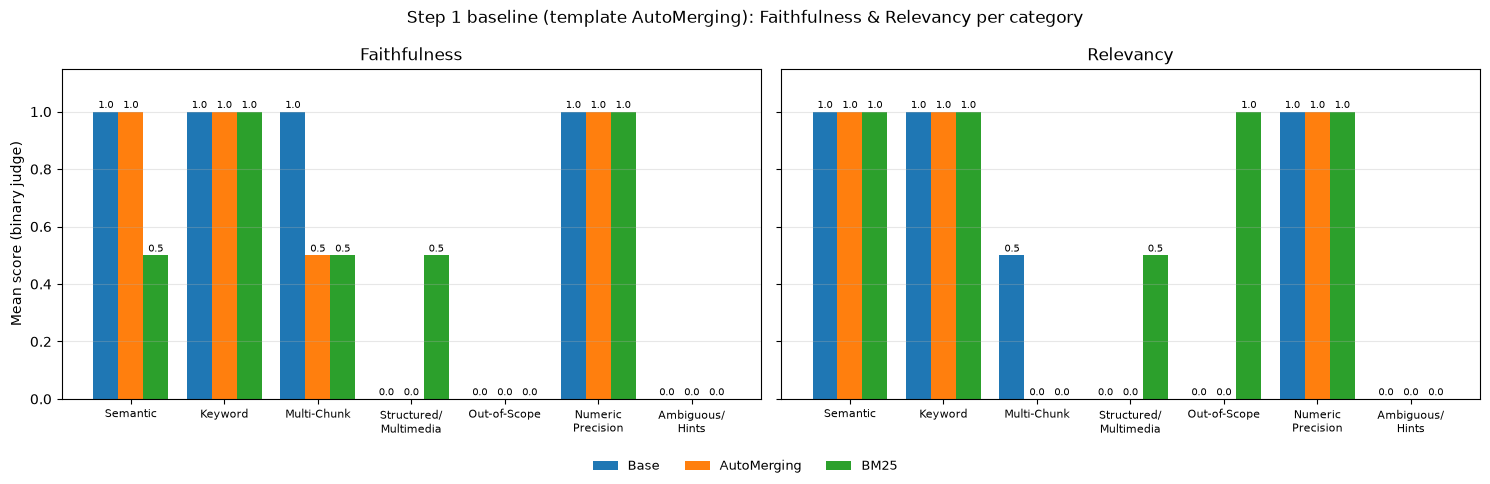

In [13]:
baseline_engines = {"Base": base_query_engine, "AutoMerging": auto_query_engine, "BM25": bm25_query_engine}
baseline_results = asyncio.run(run_evaluation(baseline_engines, test_set, "results/step1_baseline.csv"))

overall, per_cat = summarize(baseline_results)
print("=== Baseline: mean scores per retriever ===")
print(overall.round(3).to_string())
display(per_cat.round(2))
plot_by_category(baseline_results, "Step 1 baseline (template AutoMerging): Faithfulness & Relevancy per category",
                 "figures/step1_baseline_by_category.png")


In [14]:
# Full answers, needed to hand-check refusals (Out-of-Scope) and answers that claim more than the document says (Ambiguous/Hints)
displayify_df(baseline_results.pivot(index=["Category", "Question"], columns="Retriever", values="Response")
              .reindex(columns=list(baseline_engines)))


### 1.4 Bug hunt: the template's AutoMerging retriever never merges
An auto-merging retriever needs a **node hierarchy**: small leaf chunks that point to larger parent chunks, and the parents must be in the docstore so the retriever can swap a group of sibling leaves for their parent.

The template builds `nodes` with a flat `SentenceSplitter`, so no node has a `parent_node`, and the docstore behind `index.storage_context` holds only those flat chunks. `AutoMergingRetriever` therefore never finds a parent to merge into and quietly returns the plain top-k vector results. It runs without errors but it is just a duplicate of the Base retriever. The checks below show this.

In [15]:
# Evidence 1: no node in the template index has a parent, so nothing can ever be merged
has_parent = sum(n.parent_node is not None for n in nodes)
print(f"Template nodes with a parent node: {has_parent} / {len(nodes)}")
print(f"Docs in the template docstore:     {len(index.storage_context.docstore.docs)} (same flat chunks, no larger parents)")

# Evidence 2: the 'auto-merging' results are identical to the plain vector results for every test question
def retrieved_ids(retriever, q):
    return [n.node.node_id for n in retriever.retrieve(q)]

identical = sum(retrieved_ids(base_retriever, q) == retrieved_ids(auto_merging_retriever, q) for q in test_set["Question"])
print(f"Questions where AutoMerging == Base retrieval: {identical} / {len(test_set)}")


Template nodes with a parent node: 0 / 74
Docs in the template docstore:     74 (same flat chunks, no larger parents)
Questions where AutoMerging == Base retrieval: 11 / 11


**Fix:** parse the documents with a `HierarchicalNodeParser` (parents of 1024 and 512 tokens, leaves of 256 tokens to match the template chunk size), store **all** levels in the docstore, index only the **leaf** nodes, and give the `AutoMergingRetriever` that storage context. The top-k of 3 is applied to the leaves before merging. A parent replaces its children when more than half of them are retrieved (`simple_ratio_thresh=0.5`, the default).

In [16]:
from llama_index.core import StorageContext
from llama_index.core.node_parser import HierarchicalNodeParser, get_leaf_nodes, get_root_nodes

hier_parser = HierarchicalNodeParser.from_defaults(chunk_sizes=[1024, 512, 256])
hier_nodes = hier_parser.get_nodes_from_documents(documents)
leaf_nodes = get_leaf_nodes(hier_nodes)
print(f"Hierarchical nodes: {len(hier_nodes)} total, {len(get_root_nodes(hier_nodes))} roots, {len(leaf_nodes)} leaves")

# All levels go into the docstore so parents can be looked up; only leaves are embedded and searched
auto_storage_context = StorageContext.from_defaults()
auto_storage_context.docstore.add_documents(hier_nodes)
auto_index = VectorStoreIndex(leaf_nodes, storage_context=auto_storage_context, embed_model=embed_model)

auto_merging_retriever_fixed = AutoMergingRetriever(
    auto_index.as_retriever(similarity_top_k=TOP_K), auto_storage_context, verbose=False)
auto_query_engine_fixed = RetrieverQueryEngine.from_args(auto_merging_retriever_fixed)


Hierarchical nodes: 139 total, 18 roots, 84 leaves


In [17]:
# Verify: compare leaf-level retrieval (before merging) with what the fixed AutoMerging retriever returns
leaf_retriever = auto_index.as_retriever(similarity_top_k=TOP_K)
leaf_ids = {n.node_id for n in leaf_nodes}

rows = []
for q in test_set["Question"]:
    before = leaf_retriever.retrieve(q)
    after = auto_merging_retriever_fixed.retrieve(q)
    rows.append({
        "Question": q[:70],
        "Leaves retrieved": len(before),
        "Nodes after merge": len(after),
        "Merged parents": sum(n.node.node_id not in leaf_ids for n in after),
        "Chars before": sum(len(n.node.get_content()) for n in before),
        "Chars after": sum(len(n.node.get_content()) for n in after),
    })
merge_check = pd.DataFrame(rows)
display(merge_check)
print(f"Questions where at least one merge happened: {(merge_check['Merged parents'] > 0).sum()} / {len(merge_check)}")


,Question,Leaves retrieved,Nodes after merge,Merged parents,Chars before,Chars after
0,What can someone do in their day-to-day life to anticipate when a migr,3,3,1,770,770
1,How can people living with migraine cope with feeling judged or dismis,3,2,1,1808,2666
2,"What is eptinezumab-jjmr, how is it given, and how often?",3,3,0,2070,2070
3,"Which monoclonal antibodies that block CGRP are mentioned, and what ar",3,2,1,1626,1858
4,What classes of preventive medication can a doctor prescribe for chron,3,2,2,1241,1585
5,How is sleep connected to migraine according to the different sections,3,3,1,464,464
6,What are the four stages of a migraine and how long does each stage la,3,3,0,1265,1265
7,"According to the headache types table, what are the location, type of",3,3,0,1085,1085
8,How much does a VYEPTI infusion cost per dose with insurance?,3,2,1,1583,1506
9,What percentage of people with fibromyalgia also have chronic migraine,3,3,0,1821,1821


Questions where at least one merge happened: 7 / 11


In [18]:
# Show the merge with the largest context growth: leaves retrieved, and the parent that replaced them
best_q = test_set["Question"].iloc[(merge_check["Chars after"] - merge_check["Chars before"]).idxmax()]
print("Question:", best_q)
print("Before merge (top-3 leaves):")
for n in leaf_retriever.retrieve(best_q):
    print(f"  leaf {n.node.node_id[:8]}  parent={n.node.parent_node.node_id[:8]}  {len(n.node.get_content())} chars")
print("After merge:")
for n in auto_merging_retriever_fixed.retrieve(best_q):
    if n.node.node_id in leaf_ids:
        print(f"  leaf   {n.node.node_id[:8]}  {len(n.node.get_content())} chars")
    else:
        print(f"  PARENT {n.node.node_id[:8]}  {len(n.node.get_content())} chars, {len(n.node.child_nodes)} children")


Question: How can people living with migraine cope with feeling judged or dismissed by others?
Before merge (top-3 leaves):
  leaf 898eb7a7  parent=19833ec0  737 chars
  leaf c422fcd0  parent=a88f2318  916 chars
  leaf c12a68db  parent=19833ec0  155 chars
After merge:
  PARENT 19833ec0  1750 chars, 3 children
  leaf   c422fcd0  916 chars


### 1.5 Baseline with the fixed AutoMerging retriever
Base and BM25 are unchanged, so I re-ran only the fixed AutoMerging engine and combined its rows with the earlier Base and BM25 rows. **From here on, `auto_query_engine_fixed` is the AutoMerging retriever.**

results/step1_fixed_auto.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
AutoMerging (fixed) Retriever: 0.4545

✅ Relevancy Comparison
AutoMerging (fixed) Retriever: 0.4545
=== Step 1: mean scores per retriever ===
                     Faithfulness  Relevancy
Retriever                                   
Base                        0.636      0.545
BM25                        0.545      0.636
AutoMerging (buggy)         0.545      0.455
AutoMerging (fixed)         0.455      0.455


Faithfulness                           \
Retriever                     Base BM25 AutoMerging (buggy)   
Category                                                      
Semantic                       1.0  0.5                 1.0   
Keyword                        1.0  1.0                 1.0   
Multi-Chunk                    1.0  0.5                 0.5   
Structured/Multimedia          0.0  0.5                 0.0   
Out-of-Scope                   0.0  0.0                 0.0   
Numeric Precision              1.0  1.0                 1.0   
Ambiguous/Hints                0.0  0.0                 0.0   

                                          Relevancy                           \
Retriever             AutoMerging (fixed)      Base BM25 AutoMerging (buggy)   
Category                                                                       
Semantic                              0.5       1.0  1.0                 1.0   
Keyword                               1.0       1.0  1.0                 1.0   
Multi-Chunk                           0.5       0.5  0.0                 0.0   
Structured/Multimedia                 0.0       0.0  0.5                 0.0   
Out-of-Scope                          0.0       0.0  1.0                 0.0   
Numeric Precision                     1.0       1.0  1.0                 1.0   
Ambiguous/Hints                       0.0       0.0  0.0                 0.0   

                                           
Retriever             AutoMerging (fixed)  
Category                                   
Semantic                              0.5  
Keyword                               1.0  
Multi-Chunk                           0.5  
Structured/Multimedia                 0.0  
Out-of-Scope                          0.0  
Numeric Precision                     1.0  
Ambiguous/Hints                       0.0

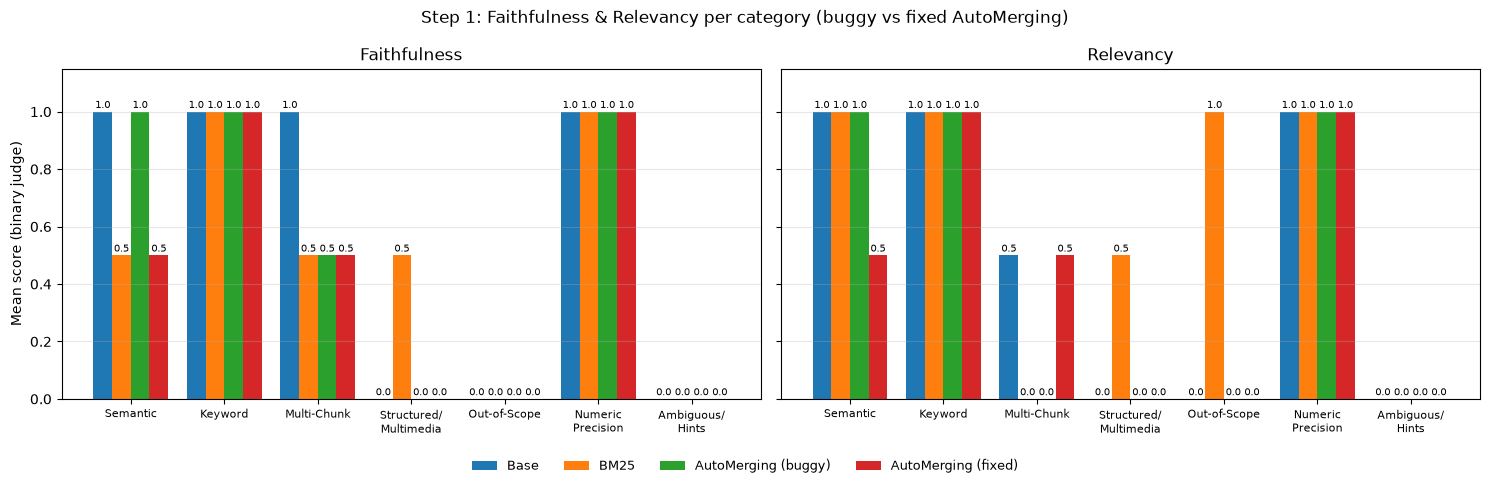

In [19]:
fixed_auto_results = asyncio.run(run_evaluation({"AutoMerging (fixed)": auto_query_engine_fixed}, test_set,
                                                "results/step1_fixed_auto.csv", show_table=False))
step1_results = pd.concat([
    baseline_results[baseline_results["Retriever"] != "AutoMerging"],
    baseline_results[baseline_results["Retriever"] == "AutoMerging"].assign(Retriever="AutoMerging (buggy)"),
    fixed_auto_results,
], ignore_index=True)
step1_results.to_csv("results/step1_final.csv", index=False)

overall, per_cat = summarize(step1_results)
print("=== Step 1: mean scores per retriever ===")
print(overall.round(3).to_string())
display(per_cat.round(2))
plot_by_category(step1_results, "Step 1: Faithfulness & Relevancy per category (buggy vs fixed AutoMerging)",
                 "figures/step1_by_category.png")


In [20]:
# Side-by-side answers for the hand-checked categories
check = step1_results[step1_results["Category"].isin(["Out-of-Scope", "Ambiguous/Hints", "Structured/Multimedia"])]
displayify_df(check.pivot(index=["Category", "Question"], columns="Retriever", values="Response"))


### 1.6 Analysis: retrieval trade-offs

**Results (TOP_K = 3, 11 questions; binary judges, so one question is about 9 points)**

| Retriever | Faithfulness | Relevancy |
|---|---|---|
| Base (vector) | 0.636 | 0.545 |
| BM25 | 0.545 | 0.636 |
| AutoMerging (template, buggy) | 0.545 | 0.455 |
| AutoMerging (fixed) | 0.455 | 0.455 |

**Noise first.** The template AutoMerging retriever returned exactly the same chunks as Base on 11/11 questions, yet scored about 9 points lower. With binary judges and 11 questions, a one-question gap is answer-LLM and judge noise, so I compare categories, not overall averages.

**Where each retriever wins.** *Keyword-Heavy* and *Numeric Precision* were answered correctly by every retriever: rare tokens (eptinezumab-jjmr, CGRP, 55%) dominate both the BM25 score and the embedding. BM25 was the only retriever to answer the *table* question correctly, because the question repeats the table's exact words ("tension-type", "location", "duration"); the vector retrievers matched prose about headache types and the LLM filled gaps from general knowledge ("steady, dull pain"), so the judge marked them unfaithful. On the first *Semantic* question BM25 also won, since the "track sleep, energy and stress" item shares the words "attack" and "migraine"; the vector answer ("track your triggers") was vaguer. Base was strongest on *Multi-Chunk*, where wording varies across sections, but no retriever retrieved both halves of the sleep answer: with k=3 and 256-token chunks all three slots went to the news section.

**Where all fail (hand-checked).** The *image-only* stages question scored 0 everywhere: its answer exists only as pixels, so every retriever answered from general knowledge (target for Step 3). On *Ambiguous/Hints* every retriever claimed migraine "runs in families", which the document never states; faithfulness 0 is correct. On *Out-of-Scope*, no retriever invented a price: all deflected to the insurer, several with the VYEPTI phone number from the document. That is effectively a correct refusal, although none said the document lacks the information, so the judge's 0 understates it.

### 1.7 Bug hunt summary

* **Bug.** The template passes flat `SentenceSplitter` nodes to `AutoMergingRetriever`. Those nodes have no `parent_node`, and the docstore contains only the same 74 flat chunks. Merging needs a parent to look up, so the retriever silently does nothing and acts as a plain top-k vector retriever.
* **Evidence.** 0/74 template nodes have a parent, and auto-merging retrieval was identical to Base retrieval on **11/11** questions.
* **Fix.** `HierarchicalNodeParser(chunk_sizes=[1024, 512, 256])` produces 139 nodes (18 roots, 84 leaves). All levels go into the docstore, only the leaves are indexed, and `AutoMergingRetriever` is given that storage context, with k=3 applied to the leaves.
* **Verification.** Merges now happen on 7/11 questions; on the stigma question two siblings (737 + 155 chars) were replaced by their 1,750-char parent. The fixed retriever does not score higher here (0.455 / 0.455): many leaves are small fragments of the scrambled multi-column text, so contexts shrink when no merge triggers. Better parsing (Step 2) should help it most. **The fixed version is used from here on.**


## Step 2: Optimizing the Ingestion Pipeline
All retrieval metrics in this step use the **vector (base) retriever only** with `TOP_K = 3`, scored on synthetic datasets built with `generate_question_context_pairs`. This isolates the effect of ingestion and does not use the Step 1 questions.

### 2.1 Document structure analysis
First, profile each page: word count, fonts, detected tables, and whether text crosses the page midline. Then look at what the template's `SimpleDirectoryReader` actually produced.

In [21]:
import pdfplumber
from collections import Counter

with pdfplumber.open(pdf_path) as pdf:
    font_total, font_alnum = Counter(), Counter()
    profile = []
    for i, page in enumerate(pdf.pages, start=1):
        for c in page.chars:
            font_total[c["fontname"]] += 1
            font_alnum[c["fontname"]] += c["text"].isalnum()
        profile.append({
            "page": i,
            "words": len(page.extract_words()),
            "images": len(page.images),
            "tables (>=4 rows)": sum(len(t.rows) >= 4 for t in page.find_tables()),
            "rotated chars": sum(not c["upright"] for c in page.chars),
        })
display(pd.DataFrame(profile).set_index("page").T)

garbled = {f: font_total[f] for f in font_total if font_alnum[f] / font_total[f] < 0.5}
print(f"Fonts with no usable Unicode mapping (<50% letters/digits): {len(garbled)} fonts, "
      f"{sum(garbled.values())} chars, e.g. {sorted(garbled)[:3]}")


page,1,2,3,4,5,6,7,8,9
words,56,170,357,341,159,288,577,525,125
images,2,1,1,0,1,10038,0,0,2
tables (>=4 rows),0,0,0,0,1,0,0,0,0
rotated chars,0,12,38,0,0,37,0,0,73


Fonts with no usable Unicode mapping (<50% letters/digits): 15 fonts, 1621 chars, e.g. ['AAAAAC+SourceSansVariable-Roman', 'AAAAAF+SourceSansVariable-Roman', 'AAAAAJ+SourceSansVariable-Roman']


In [22]:
# What the template reader produced: column text interleaved + garbled headings (page 7 'Treatment Smarts')
template_p7 = next(d for d in documents if d.metadata.get("page_label") == "7").text
print(template_p7[:900])


/gid00020/gid00006/gid00004/gid00021/gid00010/gid00016/gid00015/gid00001/gid00001/gid00021/gid00016/gid00017/gid00010/gid00004/gid00001/gid01194/gid00020/gid00006/gid00004/gid00021/gid00010/gid00016/gid00015/gid00001/gid00001/gid00021/gid00016/gid00017/gid00010/gid00004/gid00001/gid01194
THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF  | WWW.WEBMD.COM 11
/gid00021/gid00019/gid00006/gid00002/gid00021/gid00014/gid00006/gid00015/gid00021/gid00001/gid00020/gid00014/gid00002/gid00019/gid00021/gid00020/gid00001/gid00001/gid00004/gid00009/gid00019/gid00016/gid00015/gid00010/gid00004/gid00001/gid00014/gid00010/gid00008/gid00019/gid00002/gid00010/gid00015/gid00006/gid00001/gid01194
/gid00024
hen you have chronic migraine, you’ll need 
medicine for relief during an attack and medi-
cine to prevent future attacks. If your medicine 
isn’t working, don’t give up. There are more opti


**Findings**

| Issue | Where | Effect on RAG |
|---|---|---|
| **Multi-column magazine layout** (2 columns, side boxes, pull quotes) | pages 3, 6, 7, 8, 9 | The default reader merges lines across columns, so sentences from unrelated stories get mixed into one chunk |
| **Fonts with no Unicode map** (headings, drop caps, the contents page, *Lizzy's tips*) | 15+ font subsets, about 1,600 chars | Extracted as random symbols (`4"#$@4%GJ#!@G`). These add noise to embeddings and BM25 scores |
| **Missing glyphs / `(cid:N)` codes** | page 4 (VYEPTI) | Words like "ay cause" for "may cause". Not recovered: page 4's OCR blocks were filtered as duplicates of the text layer (Step 3) |
| **Rotated photo credits, running footers, characters printed twice** | every page | Noise such as `GETTY IMAGES` and `THIS CONTENT IS CREATED…` repeated in many chunks |
| **One real table** (Headache Types) | page 5 | The template's `tabula` output is a single markdown blob with wrapped cells split over many rows, plus a junk "table" made from the contents page |
| **Image-only content** (Migraine Stages graphic, cover, comorbidities figure) | pages 1, 2, 5, 6 | Invisible to text extraction (Step 3) |


### 2.2 Layout-aware loader (pdfplumber)
Design decisions, one per finding above:
* **Reading order:** recursive **XY-cut** on word boxes. Split at the widest empty gap between columns first (columns, read left to right). If there is none, split at the largest horizontal gap (blocks, read top to bottom). I remove running headers and footers *before* the cut, because a full-width footer would otherwise hide the gap between columns.
* **Noise:** drop characters from garbled fonts (detected automatically by letter/digit ratio), rotated characters (photo credits), characters printed twice (`dedupe_chars`), `(cid:N)` codes and boilerplate lines.
* **Line joining:** lines are grouped by vertical overlap, so mixed font sizes such as "20 *to* 50" stay together. End-of-line hyphens are removed only when the joined word occurs elsewhere in the document ("medi-cine" becomes "medicine", but "back-to-back" keeps its hyphens).
* **Tables:** characters inside a table's box are removed from the page text, and each table **row becomes one sentence that is complete on its own** (`Headache Type: Migraine. Location: Unilateral. …`). A row is never split across chunks, and every chunk carries its column names.
* **Deterministic IDs:** every Document and node gets a stable ID, so cached synthetic datasets stay valid when the notebook is re-run.

In [23]:
import re
from collections import Counter
import pdfplumber
from llama_index.core import Document

BOILERPLATE = [
    r"THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD",
    r"REAL STORIES \| CHRONIC MIGRAINE \| WINTER 2025",
    r"^\d{1,2}$",                                  # lone page numbers
]
_BOILER_RE = [re.compile(p) for p in BOILERPLATE]


def find_garbled_fonts(pdf, max_alnum_ratio=0.5):
    """Fonts whose glyphs have no usable Unicode mapping extract as random symbols
    (e.g. '4"#$@4%GJ#!@G'). Flag a font when under half of its characters are letters/digits."""
    total, alnum = Counter(), Counter()
    for page in pdf.pages:
        for c in page.chars:
            total[c["fontname"]] += 1
            alnum[c["fontname"]] += c["text"].isalnum()
    return {f for f in total if alnum[f] / total[f] < max_alnum_ratio}


def _gaps(intervals, min_gap):
    """Whitespace gaps (start, end) of at least min_gap along one axis."""
    intervals = sorted(intervals)
    gaps, cur_end = [], intervals[0][1]
    for a, b in intervals[1:]:
        if a - cur_end >= min_gap:
            gaps.append((cur_end, a))
        cur_end = max(cur_end, b)
    return gaps


def xy_cut(words, min_col_gap=9.0, min_row_gap=6.0):
    """Recursive XY-cut: split at the widest empty gap between columns first (columns, read left to right),
    otherwise at horizontal gaps (blocks, read top to bottom). Returns word blocks in reading order."""
    if len(words) <= 1:
        return [words]
    col_gaps = _gaps([(w["x0"], w["x1"]) for w in words], min_col_gap)
    if col_gaps:
        a, b = max(col_gaps, key=lambda g: g[1] - g[0])
        cut = (a + b) / 2
        return (xy_cut([w for w in words if w["x1"] <= cut], min_col_gap, min_row_gap)
                + xy_cut([w for w in words if w["x0"] >= cut], min_col_gap, min_row_gap))
    row_gaps = _gaps([(w["top"], w["bottom"]) for w in words], min_row_gap)
    if not row_gaps:
        return [words]
    a, b = max(row_gaps, key=lambda g: g[1] - g[0])
    cut = (a + b) / 2
    return (xy_cut([w for w in words if w["bottom"] <= cut], min_col_gap, min_row_gap)
            + xy_cut([w for w in words if w["top"] >= cut], min_col_gap, min_row_gap))


def block_to_lines(block):
    """Group a block's words into text lines: a word joins a line when its vertical centre falls
    inside the line's extent (works even with mixed font sizes such as a large '20' next to a small 'to')."""
    lines = []
    for w in sorted(block, key=lambda w: w["top"]):
        centre = (w["top"] + w["bottom"]) / 2
        for line in lines:
            if line["top"] <= centre <= line["bottom"]:
                line["words"].append(w)
                line["top"], line["bottom"] = min(line["top"], w["top"]), max(line["bottom"], w["bottom"])
                break
        else:
            lines.append({"top": w["top"], "bottom": w["bottom"], "words": [w]})
    lines.sort(key=lambda l: l["top"])
    return [" ".join(x["text"] for x in sorted(l["words"], key=lambda x: x["x0"])) for l in lines]


def drop_boilerplate_words(words, tol=2.0):
    """Remove running headers/footers *before* layout analysis: a full-width footer line would
    otherwise block the gap between columns and force the XY-cut to slice across both columns."""
    rows = {}
    for w in words:
        key = next((k for k in rows if abs(k - w["top"]) <= tol), w["top"])
        rows.setdefault(key, []).append(w)
    keep = []
    for row in rows.values():
        text = " ".join(x["text"] for x in sorted(row, key=lambda x: x["x0"]))
        if not any(r.search(text) for r in _BOILER_RE):
            keep.extend(row)
    return keep


def join_lines(lines, vocab):
    """Join wrapped lines into one paragraph, repairing end-of-line hyphenation
    ('medi-' + 'cine' -> 'medicine') only when the joined word occurs elsewhere in the document."""
    text = ""
    for line in lines:
        if not text:
            text = line
        elif text.endswith("-"):
            head = re.search(r"(\w+)-$", text)
            tail = re.match(r"(\w+)", line)
            if head and tail and (head.group(1) + tail.group(1)).lower() in vocab:
                text = text[:-1] + line
            else:
                text = text + line
        else:
            text = text + " " + line
    return text


def table_to_row_texts(table, page):
    """Turn a pdfplumber table into one sentence per row, complete on its own, e.g.
    'Headache type: Migraine. Location: Unilateral. ...'. Rows whose first cell is empty are
    continuations of the previous row (wrapped bullet lists) and are merged into it."""
    # The italic caption ('Table 1: Headache Types') overlaps the header row's box, so drop italic chars
    region = page.crop(table.bbox).filter(
        lambda o: o["object_type"] != "char" or "Italic" not in o["fontname"])
    rows = region.extract_table(
        {"vertical_strategy": "text", "horizontal_strategy": "lines"})
    def clean(cell):
        text = re.sub(r"\s+", " ", (cell or "").replace("•", " ")).strip()
        return re.sub(r"(\w)- (\w)", r"\1-\2", text)          # 'Tension- type' -> 'Tension-type'
    header = [clean(h) for h in rows[0]]
    records = []
    for row in rows[1:]:
        cells = [clean(c) for c in row]
        if not any(cells):
            continue
        if cells[0]:
            records.append(cells)
        elif records:
            records[-1] = [f"{a} {b}".strip() for a, b in zip(records[-1], cells)]
    texts = []
    for rec in records:
        parts = [f"{h or 'Notes'}: {v}" for h, v in zip(header, rec) if v]
        texts.append(". ".join(parts) + ".")
    return header, texts


def load_webmd_pdfplumber(pdf_path, min_table_rows=4):
    """Layout-aware loader: one Document per page (reading order via XY-cut, garbled fonts and
    rotated photo credits removed, boilerplate dropped) plus one Document per table row."""
    page_docs, table_docs = [], []
    with pdfplumber.open(pdf_path) as pdf:
        bad_fonts = find_garbled_fonts(pdf)
        vocab = set()
        for page in pdf.pages:
            vocab.update(w.lower() for w in re.findall(r"[A-Za-z]+", page.extract_text() or ""))

        for page_no, page in enumerate(pdf.pages, start=1):
            tables = [t for t in page.find_tables() if len(t.rows) >= min_table_rows]
            boxes = [t.bbox for t in tables]

            def keep(obj):
                if obj["object_type"] != "char":
                    return True
                if not obj.get("upright", True) or obj["fontname"] in bad_fonts:
                    return False
                cx, cy = (obj["x0"] + obj["x1"]) / 2, (obj["top"] + obj["bottom"]) / 2
                return not any(b[0] <= cx <= b[2] and b[1] <= cy <= b[3] for b in boxes)

            words = page.dedupe_chars().filter(keep).extract_words(keep_blank_chars=False, use_text_flow=False)
            words = drop_boilerplate_words(words)
            paragraphs = []
            for block in xy_cut(words):
                lines = [l for l in block_to_lines(block)
                         if not any(r.search(l) for r in _BOILER_RE)]
                if lines:
                    paragraphs.append(re.sub(r"\(cid:\d+\)", "", join_lines(lines, vocab)))
            text = "\n\n".join(p for p in paragraphs if len(p) > 1)
            page_docs.append(Document(text=text, metadata={"page_label": str(page_no), "source": "text"}))

            for t in tables:
                header, rows = table_to_row_texts(t, page)
                for row in rows:
                    table_docs.append(Document(text=row, metadata={"page_label": str(page_no), "source": "table"}))
    return page_docs, table_docs



In [24]:
page_docs, table_docs = load_webmd_pdfplumber(pdf_path)
for d in page_docs:
    d.id_ = f"p{d.metadata['page_label']}"
for i, d in enumerate(table_docs):
    d.id_ = f"t{d.metadata['page_label']}-{i}"
clean_docs = page_docs + table_docs

print(f"{len(page_docs)} page documents, {len(table_docs)} table-row documents, "
      f"{sum(len(d.text) for d in clean_docs):,} chars (template: {sum(len(d.text) for d in documents):,})")
print("\n--- page 7, layout-aware ---")
print(page_docs[6].text[:900])
print("\n--- table rows ---")
for d in table_docs:
    print(d.text[:160], "...")


9 page documents, 4 table-row documents, 15,230 chars (template: 34,136)

--- page 7, layout-aware ---
By Sonya Collins Reviewed by Melinda Ratini, DO, MS, WebMD Medical Reviewer

hen you have chronic migraine, you’ll need medicine for relief during an attack and medicine to prevent future attacks. If your medicine isn’t working, don’t give up. There are more options available today than ever before. “With methodical, sustained attempts at treatment, we are usually able to find a treatment or treatments that will improve your quality of life,” says Elizabeth W. Loder, MD, MPH, a headache specialist and professor of neurology at Harvard Medical School in Boston.

Keep over-the-counter or prescription pain relievers within your reach to take whenever you feel the first signs of an attack. “The earlier you treat, the more likely you are to get out of this bad episode that’s coming,” says Moises Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.


### 2.3 Retrieval evaluation helpers
* `build_nodes`: `SentenceSplitter` plus embedding through an `IngestionPipeline`, with node IDs `<doc id>_<chunk index>`.
* `get_dataset` (defined in Section 5): `generate_question_context_pairs`, cached per configuration. Every chunking produces different chunks, so every configuration gets its own synthetic dataset.
* `eval_vector`: the template's `RetrieverEvaluator` (MRR, hit rate, precision, recall) on a fresh vector index of those nodes, optionally printed with the template's `display_retriever_eval_results`. Each synthetic question has exactly **one** relevant chunk, so recall equals hit rate, and precision@3 is at most 1/3.

In [25]:
from llama_index.core.node_parser import SentenceSplitter
from llama_index.core.ingestion import IngestionPipeline

def build_nodes(docs, chunk_size, chunk_overlap, paragraph_separator="\n\n\n"):
    """Chunk + embed documents. Node ids are deterministic so cached datasets stay valid."""
    splitter = SentenceSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap,
                                paragraph_separator=paragraph_separator,
                                id_func=lambda i, doc: f"{doc.doc_id}_{i}")
    return IngestionPipeline(transformations=[splitter, embed_model]).run(documents=docs)

def eval_vector(nodes, dataset, top_k=TOP_K, show_as=None):
    """Hit rate / MRR / precision / recall of a vector retriever over these nodes.
    show_as: also print the means with the template's display_retriever_eval_results (Section 5)."""
    retriever = VectorStoreIndex(nodes, embed_model=embed_model).as_retriever(similarity_top_k=top_k)
    evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=retriever)
    results = asyncio.run(evaluator.aevaluate_dataset(dataset, workers=8))
    if show_as:
        display_retriever_eval_results(show_as, results)
    metrics = pd.DataFrame([r.metric_vals_dict for r in results]).mean().to_dict()
    return {"Nodes": len(nodes), "Questions": len(dataset.queries), **{k.replace("_", " ").title(): v for k, v in metrics.items()}}

def run_config(name, docs, chunk_size, chunk_overlap, show_as=None, **kw):
    """Chunk + embed with one setting, then score the vector retriever on that setting's own synthetic dataset."""
    nodes = build_nodes(docs, chunk_size, chunk_overlap, **kw)
    return nodes, {"Config": name, **eval_vector(nodes, get_dataset(name, nodes), show_as=show_as)}


### 2.4 Template baseline (original ingestion settings)
This is the template's ingestion from Section 2 (`SimpleDirectoryReader` + tabula markdown, `SentenceSplitter(256, overlap=0)`), scored on the template's synthetic `qa_dataset` from Section 5.

In [26]:
baseline_nodes = nodes
baseline_row = {"Config": "baseline_default_256_0", **eval_vector(baseline_nodes, qa_dataset, show_as="Base Retriever (template ingestion)")}
display(pd.DataFrame([baseline_row]).set_index("Config").round(3))


=== Base Retriever (template ingestion) ===
Mean:
 mrr          0.329427
hit_rate     0.382812
precision    0.127604
recall       0.382812
dtype: float64 



,Nodes,Questions,Mrr,Hit Rate,Precision,Recall
Config,,,,,,
baseline_default_256_0,74,128,0.329,0.383,0.128,0.383


### 2.5 Systematic chunk-size ablation
`chunk_size` ∈ {64, 128, 256, 512} with `chunk_overlap = 32`, on the layout-aware documents from 2.2, using the vector retriever only.

Every chunking produces different chunks, so each one gets its own synthetic dataset. The standard metric counts a hit only when the exact source chunk ID comes back. Small chunks give narrow questions and many similar wrong chunks. Large chunks give few, easy targets. With overlap, a neighbouring chunk that contains the same answer still counts as a miss. To compare the settings on equal terms I also ran a **pooled cross-check**:
* all questions from the four ablation datasets are asked of every configuration;
* a retrieved chunk counts as relevant when it shares at least half of the shorter chunk's word trigrams with the chunk the question was generated from.

Because relevance is judged on text rather than IDs, the same test also works across pipelines with different documents (2.6 and 2.7).

In [27]:
ablation_rows, ablation_nodes = [], {}
for cs in [64, 128, 256, 512]:
    nodes_cs, row = run_config(f"ablation_cs{cs}_ov32", clean_docs, cs, 32)
    ablation_nodes[cs] = nodes_cs
    ablation_rows.append({"Chunk Size": cs, **row})
ablation_df = pd.DataFrame(ablation_rows).set_index("Chunk Size").drop(columns="Config")
display(ablation_df.round(3))


,Nodes,Questions,Mrr,Hit Rate,Precision,Recall
Chunk Size,,,,,,
64,110,142,0.667,0.810,0.270,0.810
128,43,62,0.777,0.935,0.312,0.935
256,23,36,0.866,0.972,0.324,0.972
512,16,24,0.840,0.958,0.319,0.958


In [28]:
def trigrams(text):
    toks = re.findall(r"[a-z0-9%]+", text.lower())
    return {tuple(toks[i:i + 3]) for i in range(len(toks) - 2)}

def text_relevant(chunk_tri, target_tri, min_frac=0.5):
    """Relevant if the two chunks share >= min_frac of the shorter chunk's word trigrams."""
    if not chunk_tri or not target_tri:
        return False
    return len(chunk_tri & target_tri) >= min_frac * min(len(chunk_tri), len(target_tri))

def question_set(dataset):
    """[(question, trigrams of its source chunk)] from a synthetic dataset."""
    return [(q, trigrams(dataset.corpus[dataset.relevant_docs[qid][0]])) for qid, q in dataset.queries.items()]

def text_eval(nodes, qset, top_k=TOP_K):
    """Hit rate / MRR when relevance is judged by text overlap instead of node ids."""
    retriever = VectorStoreIndex(nodes, embed_model=embed_model).as_retriever(similarity_top_k=top_k)
    hits, rr = [], []
    for q, target in qset:
        ranks = [i for i, n in enumerate(retriever.retrieve(q), start=1)
                 if text_relevant(trigrams(n.node.get_content()), target)]
        hits.append(bool(ranks))
        rr.append(1 / ranks[0] if ranks else 0.0)
    return {"Pooled Hit Rate": float(np.mean(hits)), "Pooled MRR": float(np.mean(rr))}

def retrieval_report(retriever, qset, k=TOP_K):
    """Hit rate, MRR, precision@k, recall@k with text-overlap relevance (one source chunk per question).
    Works for any retriever, including AutoMerging, whose merged parents have ids that no dataset contains."""
    hit, rr, prec = [], [], []
    for q, target in qset:
        flags = [text_relevant(trigrams(n.node.get_content()), target) for n in retriever.retrieve(q)[:k]]
        ranks = [i for i, f in enumerate(flags, start=1) if f]
        hit.append(bool(ranks))
        rr.append(1 / ranks[0] if ranks else 0.0)
        prec.append(sum(flags) / k)
    return {"Hit Rate": np.mean(hit), "MRR": np.mean(rr), "Precision": np.mean(prec), "Recall": np.mean(hit)}

# One common question set: every question from the four ablation datasets
pooled_qset = [qt for cs, n in ablation_nodes.items() for qt in question_set(get_dataset(f"ablation_cs{cs}_ov32", n))]
pooled_df = pd.DataFrame({cs: text_eval(n, pooled_qset) for cs, n in ablation_nodes.items()}).T
pooled_df.index.name = "Chunk Size"
print(f"Pooled cross-check: {len(pooled_qset)} questions asked of every chunking")
ablation_summary = ablation_df[["Nodes", "Hit Rate", "Mrr"]].join(pooled_df)
ablation_summary["Mean MRR"] = (ablation_summary["Mrr"] + ablation_summary["Pooled MRR"]) / 2
display(ablation_summary.round(3))


Pooled cross-check: 264 questions asked of every chunking


,Nodes,Hit Rate,Mrr,Pooled Hit Rate,Pooled MRR,Mean MRR
Chunk Size,,,,,,
64,110,0.810,0.667,0.860,0.789,0.728
128,43,0.935,0.777,0.920,0.781,0.779
256,23,0.972,0.866,0.913,0.802,0.834
512,16,0.958,0.840,0.909,0.758,0.799


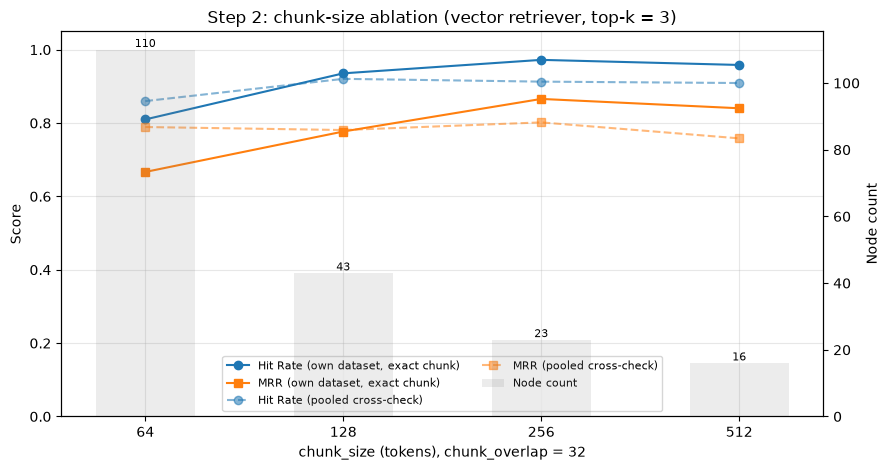

In [29]:
fig, ax1 = plt.subplots(figsize=(9, 4.8))
x = ablation_df.index.astype(str)
ax1.plot(x, ablation_df["Hit Rate"], "o-", color="C0", label="Hit Rate (own dataset, exact chunk)")
ax1.plot(x, ablation_df["Mrr"], "s-", color="C1", label="MRR (own dataset, exact chunk)")
ax1.plot(x, pooled_df["Pooled Hit Rate"], "o--", color="C0", alpha=0.55, label="Hit Rate (pooled cross-check)")
ax1.plot(x, pooled_df["Pooled MRR"], "s--", color="C1", alpha=0.55, label="MRR (pooled cross-check)")
ax1.set_xlabel("chunk_size (tokens), chunk_overlap = 32")
ax1.set_ylabel("Score")
ax1.set_ylim(0, 1.05)
ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
bars = ax2.bar(x, ablation_df["Nodes"], alpha=0.15, color="gray", width=0.5, label="Node count")
ax2.bar_label(bars, fmt="%d", fontsize=8)
ax2.set_ylabel("Node count")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower center", fontsize=8, ncol=2)
ax1.set_title("Step 2: chunk-size ablation (vector retriever, top-k = 3)")
fig.tight_layout()
fig.savefig("figures/step2_chunk_ablation.png", dpi=150, bbox_inches="tight")
plt.show()


### 2.6 Pipeline refinement at the chosen chunk size
**Chunk size:** I picked the size with the best mean of own-dataset MRR and pooled MRR. A larger window also gives the answer LLM more context per retrieved chunk, and Step 1 showed that short contexts hurt answers.

At that size I changed **one thing at a time** and kept a change only if it improved **pooled MRR**, the one measure shared by every variant (own-dataset numbers are shown too):
1. **Chunk overlap:** 0, 32 or 64 tokens.
2. **Paragraph-aware splitting:** the loader separates layout blocks with `\n\n`; `paragraph_separator="\n\n"` makes the splitter break at those boundaries first. The default `\n\n\n` never occurs, so by default it splits by sentences.
3. **Table handling:** one sentence per row (my loader) versus the template-style single tabula markdown table as one Document.

In [30]:
CHOSEN_CS = int(ablation_summary["Mean MRR"].idxmax())
print("Chosen chunk size (best mean of own and pooled MRR):", CHOSEN_CS)

def refine(step, variant, name, docs, overlap, **kw):
    nodes_v, row = run_config(name, docs, CHOSEN_CS, overlap, **kw)
    return {"Step": step, "Variant": variant, **row, **text_eval(nodes_v, pooled_qset)}

refine_rows = [refine("1. overlap", f"overlap={ov}", f"refine_cs{CHOSEN_CS}_ov{ov}", clean_docs, ov) for ov in [0, 32, 64]]
best = max(refine_rows, key=lambda r: r["Pooled MRR"])
best_ov = int(best["Variant"].split("=")[1])

para = refine("2. splitting", "paragraph-aware", f"refine_cs{CHOSEN_CS}_ov{best_ov}_para", clean_docs, best_ov,
              paragraph_separator="\n\n")
refine_rows.append(para)
use_para = para["Pooled MRR"] > best["Pooled MRR"]
para_kw = {"paragraph_separator": "\n\n"} if use_para else {}
suffix = "_para" if use_para else ""
best = para if use_para else best

tabula_doc = Document(text=all_tables_text, id_="tabula")
tab = refine("3. tables", "tabula markdown blob", f"refine_cs{CHOSEN_CS}_ov{best_ov}{suffix}_tabula",
             page_docs + [tabula_doc], best_ov, **para_kw)
refine_rows.append(tab)
use_rows = best["Pooled MRR"] >= tab["Pooled MRR"]

refine_df = pd.DataFrame(refine_rows).drop(columns="Config").set_index(["Step", "Variant"])
display(refine_df.round(3))
print(f"Kept: overlap={best_ov}, paragraph-aware splitting={use_para}, "
      f"tables={'one sentence per row' if use_rows else 'tabula markdown'}")


Chosen chunk size (best mean of own and pooled MRR): 256


Nodes  Questions    Mrr  Hit Rate  \
Step         Variant                                                   
1. overlap   overlap=0                22         32  0.859     0.969   
             overlap=32               23         36  0.815     0.972   
             overlap=64               24         36  0.815     0.917   
2. splitting paragraph-aware          24         38  0.803     0.947   
3. tables    tabula markdown blob     25         30  0.883     0.967   

                                   Precision  Recall  Pooled Hit Rate  \
Step         Variant                                                    
1. overlap   overlap=0                 0.323   0.969            0.890   
             overlap=32                0.324   0.972            0.913   
             overlap=64                0.306   0.917            0.924   
2. splitting paragraph-aware           0.316   0.947            0.905   
3. tables    tabula markdown blob      0.322   0.967            0.818   

                                   Pooled MRR  
Step         Variant                           
1. overlap   overlap=0                  0.764  
             overlap=32                 0.802  
             overlap=64                 0.841  
2. splitting paragraph-aware            0.783  
3. tables    tabula markdown blob       0.761

Kept: overlap=64, paragraph-aware splitting=False, tables=one sentence per row


### 2.7 Optimized pipeline vs the template baseline
The standard comparison uses each pipeline's own synthetic dataset. Because the template's dataset was generated from its own noisy chunks, I also asked both question sets of both pipelines, using the text-overlap relevance test.

=== Base Retriever (optimized ingestion) ===
Mean:
 mrr          0.814815
hit_rate     0.916667
precision    0.305556
recall       0.916667
dtype: float64 



,Nodes,Questions,Mrr,Hit Rate,Precision,Recall
Config,,,,,,
"Template baseline (256/0, default reader + tabula)",74,128,0.329,0.383,0.128,0.383
"Optimized (256/64, layout-aware, table rows)",24,36,0.815,0.917,0.306,0.917


MRR with text-overlap relevance (rows = pipeline, columns = question set):


,Template questions (n=128),Clean pooled questions (n=264)
Template baseline,0.349,0.556
Optimized,0.289,0.841


Template chunks that are >30% glyph garbage: 42/74; synthetic questions generated from them: 74/128
Examples: ["What is the patient's diagnosis?", "What are the patient's relevant medical codes?", 'What is the sequence of group IDs (gid) in the first part of the context?']


Template questions from clean chunks only (n=54): MRR template = 0.701, optimized = 0.685


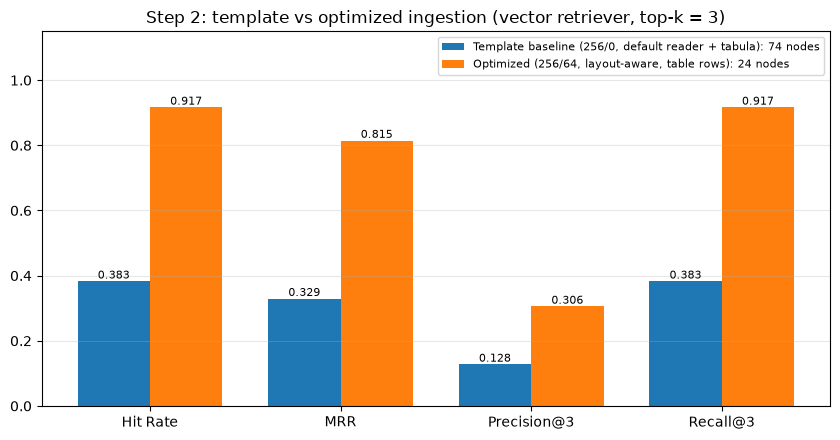

In [31]:
optimized_docs = clean_docs if use_rows else page_docs + [tabula_doc]
optimized_name = f"refine_cs{CHOSEN_CS}_ov{best_ov}{suffix}" + ("" if use_rows else "_tabula")
optimized_nodes, optimized_row = run_config(optimized_name, optimized_docs, CHOSEN_CS, best_ov,
                                           show_as="Base Retriever (optimized ingestion)", **para_kw)
opt_label = (f"Optimized ({CHOSEN_CS}/{best_ov}, layout-aware{', paragraph-aware' if use_para else ''}, "
             f"{'table rows' if use_rows else 'tabula'})")
compare_df = pd.DataFrame([{**baseline_row, "Config": "Template baseline (256/0, default reader + tabula)"},
                           {**optimized_row, "Config": opt_label}]).set_index("Config").drop(columns=[], errors="ignore")
display(compare_df.round(3))

# Cross-check: both question sets asked of both pipelines (text-overlap relevance)
baseline_qset = question_set(get_dataset("baseline_default_256_0", baseline_nodes))
cross = pd.DataFrame({
    "Template questions (n=%d)" % len(baseline_qset): {
        "Template baseline": text_eval(baseline_nodes, baseline_qset)["Pooled MRR"],
        "Optimized": text_eval(optimized_nodes, baseline_qset)["Pooled MRR"]},
    "Clean pooled questions (n=%d)" % len(pooled_qset): {
        "Template baseline": text_eval(baseline_nodes, pooled_qset)["Pooled MRR"],
        "Optimized": text_eval(optimized_nodes, pooled_qset)["Pooled MRR"]},
})
print("MRR with text-overlap relevance (rows = pipeline, columns = question set):")
display(cross.round(3))

# Why is the template's own dataset so hard? Many of its chunks are glyph-code garbage
def junk_ratio(text):
    toks = text.split()
    return sum("/gid" in t or sum(ch.isalnum() for ch in t) < len(t) / 2 for t in toks) / max(1, len(toks))

bds = get_dataset("baseline_default_256_0", baseline_nodes)
junk_chunks = sum(junk_ratio(n.get_content()) > 0.3 for n in baseline_nodes)
src_junk = {qid: junk_ratio(bds.corpus[bds.relevant_docs[qid][0]]) > 0.3 for qid in bds.queries}
print(f"Template chunks that are >30% glyph garbage: {junk_chunks}/{len(baseline_nodes)}; "
      f"synthetic questions generated from them: {sum(src_junk.values())}/{len(src_junk)}")
print("Examples:", [bds.queries[q] for q in list(bds.queries) if src_junk[q]][:3])
clean_bq = [(q, trigrams(bds.corpus[bds.relevant_docs[qid][0]])) for qid, q in bds.queries.items() if not src_junk[qid]]
print(f"Template questions from clean chunks only (n={len(clean_bq)}): MRR template = "
      f"{text_eval(baseline_nodes, clean_bq)['Pooled MRR']:.3f}, optimized = {text_eval(optimized_nodes, clean_bq)['Pooled MRR']:.3f}")

metrics = ["Hit Rate", "Mrr", "Precision", "Recall"]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
xs = np.arange(len(metrics))
for i, (name, row) in enumerate(compare_df.iterrows()):
    bars = ax.bar(xs + (i - 0.5) * 0.38, row[metrics].astype(float), 0.38, label=f"{name}: {int(row['Nodes'])} nodes")
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_xticks(xs, ["Hit Rate", "MRR", "Precision@3", "Recall@3"])
ax.set_ylim(0, 1.15)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Step 2: template vs optimized ingestion (vector retriever, top-k = 3)")
fig.tight_layout()
fig.savefig("figures/step2_baseline_vs_optimized.png", dpi=150, bbox_inches="tight")
plt.show()

# The optimized nodes are the ingestion used from here on (Steps 3-5)
final_nodes = optimized_nodes


### 2.8 Analysis: optimized ingestion vs the template

**Results (vector retriever, top-k = 3)**

| Pipeline | Nodes | Hit Rate | MRR | Precision@3 | Recall@3 |
|---|---|---|---|---|---|
| Template (default reader + tabula, 256/0) | 74 | 0.383 | 0.329 | 0.128 | 0.383 |
| **Optimized (layout-aware loader + table rows, 256/64)** | **24** | **0.917** | **0.815** | **0.306** | **0.917** |

*(Each question has one relevant chunk, so Recall@3 = Hit Rate, and Precision@3 cannot exceed 0.333.)*

**Most of the gain is parsing, not chunking.** 42 of the 74 template chunks are more than 30% glyph garbage. The garbage is `/gid00020…` codes from fonts with no Unicode map, and the two columns mixed line by line. These chunks produced 74 of the template's 128 synthetic questions, such as *"What is the sequence of group IDs (gid) in the first part of the context?"*. My loader keeps 15k characters of clean text, in the right reading order, in 24 chunks. The headache table becomes four row sentences, each complete on its own. On one shared question set (264 pooled questions, text-overlap relevance), MRR rises from 0.556 to 0.841. On the 54 template questions generated from clean template chunks, the two pipelines tie (0.701 vs 0.685). So nothing the template could retrieve was lost.

**Chunk size: 256.** Own-dataset MRR rises from 0.67 at 64 tokens to a peak of 0.87 at 256, then dips to 0.84 at 512. Over the same range the node count falls from 110 to 16. The pooled cross-check also picks 256 (0.789 / 0.781 / 0.802 / 0.758), but it is much flatter. So part of the own-dataset rise is a side effect of larger chunks giving fewer, easier targets. At 64 tokens, three chunks give the LLM only about 190 tokens of context. At 512, one chunk mixes unrelated stories.

**Refinements, one at a time.**
* *Overlap:* the own-dataset metric prefers overlap 0 (MRR 0.859 vs 0.815 at 64, on 32-36 questions). Pooled MRR prefers 64 (0.841 vs 0.764, on 264 questions). I kept 64. The pooled set is about 8x larger, and exact-ID matching counts an overlapping neighbour with the same answer text as a miss.
* *Paragraph-aware splitting* lowered pooled MRR to 0.783, so I did not keep it. Short fragments, such as single SOURCE lines, became weak chunks on their own.
* *Tabula markdown* instead of row sentences lowered pooled hit rate from 0.924 to 0.818, so I kept the row sentences. In the markdown table, a cell such as `4-72 hours` sits far from its row and column names.

**Limits:** the own-dataset sets are small at large chunk sizes (24-38 questions), and the trigram-overlap test is an approximation.


## Step 3: Extracting Information from Images (OCR)
The text layer misses two kinds of content:
1. **Images:** the *Migraine Stages* graphic on page 5 (the answer to my image-only test question), the cover and the contents page artwork.
2. **Text drawn in fonts without a Unicode map:** the section headings, the table of contents and the *Lizzy's Tips* box on page 9. In Step 2 this text was dropped because it extracts as glyph garbage.

OCR on full rendered pages covers both. Pages are rendered with PyMuPDF (`page.get_pixmap`), and I used **EasyOCR** because it installs with pip alone, which also works on Colab.

In [32]:
%pip install -q easyocr pymupdf

Note: you may need to restart the kernel to use updated packages.


### 3.1 OCR every page
Each page is rendered at 200 dpi, and EasyOCR runs with `paragraph=True`, which merges nearby text boxes into blocks; for example, the label `Aura:` and its value `five to 60 minutes` become one line. Results are cached to `ocr_cache.json`, because OCR on a CPU takes about 10 s per page.

In [33]:
import pymupdf, easyocr

def ocr_pdf_pages(path, dpi=200, cache="ocr_cache.json"):
    """{page_number: [text block, ...]} in top-to-bottom order, cached to JSON."""
    if os.path.exists(cache):
        return {int(k): v for k, v in json.load(open(cache)).items()}
    reader = easyocr.Reader(["en"], gpu=False, verbose=False)
    out = {}
    with pymupdf.open(path) as pdf:
        for i, page in enumerate(pdf, start=1):
            pix = page.get_pixmap(dpi=dpi)
            img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
            blocks = reader.readtext(img, paragraph=True)                      # [(box, text), ...]
            blocks.sort(key=lambda b: (round(b[0][0][1] / 20), b[0][0][0]))      # rows of ~20px, then x
            out[i] = [text for _, text in blocks]
    json.dump(out, open(cache, "w"), indent=1)
    return out

ocr_raw = ocr_pdf_pages(pdf_path)
print({p: len(b) for p, b in ocr_raw.items()}, "blocks per page")
print("\nPage 5 (Migraine Stages graphic):", ocr_raw[5][:9])


{1: 11, 2: 18, 3: 13, 4: 12, 5: 24, 6: 10, 7: 7, 8: 6, 9: 7} blocks per page

Page 5 (Migraine Stages graphic): ['Migraine Stages', 'Prodrome: few hours to @ few days', '02', 'Aura: five to 60 minutes', '03', 'Headache or attack: four to 72 hours', '04', 'Postdrome: 24 to 48 hours', 'Headache Types Overview Headaches are classified by the International Headache   Society into different   types based on their characteristics, causes, and  symptoms: The most common headache types are summarized in  Table 1, including cluster headaches, migraines, sinus headaches, and tension-type headaches']


### 3.2 Keep only what the text layer missed
Full-page OCR also re-reads every paragraph already extracted in Step 2. Adding those again would create near-duplicate chunks competing for the same top-3 slots, so each OCR block passes two filters:
* **Novelty:** drop the block if it is already in that page's text layer: at least 90% of its words occur on the page (this catches the OCR re-read of the table, whose cell order comes out scrambled), or, for 3+ words, at least 50% of its word trigrams do. `Headache or attack: four to 72 hours` survives: `four` and `attack` are not on page 5, and no trigram matches.
* **Junk / boilerplate:** drop blocks with fewer than two words of 3+ letters, such as `02` or `Dr Ze` (OCR fragments of photos), and the running footers.

A light clean-up fixes common EasyOCR slips (`@` to `a`, a lone `[` to `I`, `$` to `s` after a letter, stray `_`). The kept blocks are aggregated into **one Document per page** with `page_label` and `source='ocr'`.

In [34]:
OCR_BOILERPLATE = _BOILER_RE + [re.compile(r"REAL STORIES\W+CHRONIC MIGRAINE\W+WINTER 2025")]

def clean_ocr(text):
    text = re.sub(r"(?<=\s)@(?=\s)", "a", text)          # 'to @ few days' -> 'to a few days'
    text = re.sub(r"(?<=\s)\[(?=\s)", "I", text)         # 'How [ help' -> 'How I help'
    text = re.sub(r"(?<=[A-Za-z'])\$", "s", text)         # "LIZZY'$" -> "LIZZY's"
    text = re.sub(r"[_]+", "", text)
    return re.sub(r"\s+", " ", text).strip()

def is_novel(block, layer_text, word_frac=0.9, tri_frac=0.5):
    """A block is a duplicate if (almost) all its words are on the page already, or, for 3+ words,
    if half its word trigrams are. Word coverage catches OCR re-reads of the table whose cell order is
    scrambled (trigrams differ, words don't); trigrams catch re-read prose."""
    words = re.findall(r"[a-z0-9%]+", block.lower())
    layer_words = set(re.findall(r"[a-z0-9%]+", layer_text.lower()))
    if sum(w in layer_words for w in words) >= word_frac * max(1, len(words)):
        return False
    if len(words) >= 3:
        tri = trigrams(block)
        return len(tri & trigrams(layer_text)) < tri_frac * len(tri)
    return True

def real_words(block):
    return len(re.findall(r"[A-Za-z]{3,}", block))

text_layer = {int(d.metadata["page_label"]): "" for d in clean_docs}
for d in clean_docs:
    text_layer[int(d.metadata["page_label"])] += "\n" + d.text

ocr_docs, ocr_log = [], []
for page, blocks in ocr_raw.items():
    kept = []
    for b in blocks:
        b = clean_ocr(b)
        status = ("junk" if real_words(b) < 2 else
                  "boilerplate" if any(r.search(b) for r in OCR_BOILERPLATE) else
                  "kept" if is_novel(b, text_layer.get(page, "")) else "duplicate")
        ocr_log.append({"Page": page, "Status": status, "Block": b[:90]})
        if status == "kept":
            kept.append(b)
    if kept:
        ocr_docs.append(Document(text="\n".join(kept), id_=f"ocr{page}",
                                 metadata={"page_label": str(page), "source": "ocr"}))

ocr_log = pd.DataFrame(ocr_log)
print(ocr_log["Status"].value_counts().to_string())
print(f"\n{len(ocr_docs)} OCR documents, {sum(len(d.text) for d in ocr_docs):,} new characters")
displayify_df(ocr_log[ocr_log["Status"] == "kept"])


Status
duplicate      42
kept           33
junk           27
boilerplate     6

8 OCR documents, 1,268 new characters


,Page,Status,Block
0,1,kept,WebMD REAL STORIES CHRONIC MIGRAINE
1,1,kept,HEALTH SMARTS
2,1,kept,A look inside yourhead and more page 9
4,1,kept,How I help others help me page 14
5,1,kept,LIVING HEALTHY
6,1,kept,Prioritize lifestyle changes page 16
11,2,kept,WebMD CHRONIC MIGRAINE CONTENTS
12,2,kept,INSIDE THE ISSUE
15,2,kept,FIRST PERSON Being my own advocate
16,2,kept,The latest research


In [35]:
# The aggregated OCR text in a single view (ingested per page, see above)
all_ocr_text = "\n\n".join(f"[page {d.metadata['page_label']}]\n{d.text}" for d in ocr_docs)
print(all_ocr_text[:2500])


[page 1]
WebMD REAL STORIES CHRONIC MIGRAINE
HEALTH SMARTS
A look inside yourhead and more page 9
How I help others help me page 14
LIVING HEALTHY
Prioritize lifestyle changes page 16

[page 2]
WebMD CHRONIC MIGRAINE CONTENTS
INSIDE THE ISSUE
FIRST PERSON Being my own advocate
The latest research
HEALTH SMARTS A look inside yourhead and more
Here's how I help others help me through chronic migraine
TREATMENT SMARTS Manage your chronic migraine
LIVING HEALTHY Prioritize lifestyle changes

[page 3]
NEWS CHRONIC MIGRAINE
THE LATEST ON
LCHRONIC MIGRAINE

[page 5]
Migraine Stages
Prodrome: few hours to a few days
Aura: five to 60 minutes
Headache or attack: four to 72 hours
Postdrome: 24 to 48 hours

[page 6]
WebMD HEALTH SMARTS CHRONIC MIGRAINE
COMORBIDITIES These conditions often go hand-in-hand with chronic migraine.

[page 7]
TREATMENT SMARTS CHRONIC MIGRAINE
MANAGE YOUR CHRONIC MIGRAINE
When you have 15-plus headache days a month, you'Il need a multipronged treatment approach

[page 8]

### 3.3 Retrievers with and without OCR
Both conditions use the **final Step 2 ingestion** (layout-aware loader, 256-token chunks, overlap 64), and the same three retrievers as Step 1: Base (vector), BM25, and the **fixed** AutoMerging retriever (hierarchy 1024/512/256 with overlap 64; k=3 applied to the leaves). The only difference is whether the OCR documents are appended.

In [36]:
def make_engines(docs, nodes):
    """Base / BM25 / fixed AutoMerging query engines over one ingestion, all with TOP_K."""
    vec_index = VectorStoreIndex(nodes, embed_model=embed_model)
    base = vec_index.as_retriever(similarity_top_k=TOP_K)
    bm25 = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=TOP_K,
                                       stemmer=Stemmer.Stemmer("english"), language="english")
    h_nodes = HierarchicalNodeParser.from_defaults(chunk_sizes=[1024, 512, CHOSEN_CS], chunk_overlap=best_ov) \
        .get_nodes_from_documents(docs)
    storage = StorageContext.from_defaults()
    storage.docstore.add_documents(h_nodes)
    leaf_index = VectorStoreIndex(get_leaf_nodes(h_nodes), storage_context=storage, embed_model=embed_model)
    auto = AutoMergingRetriever(leaf_index.as_retriever(similarity_top_k=TOP_K), storage)
    retrievers = {"Base": base, "BM25": bm25, "AutoMerging": auto}
    return retrievers, {name: RetrieverQueryEngine.from_args(r) for name, r in retrievers.items()}

docs_no_ocr = optimized_docs
docs_ocr = optimized_docs + ocr_docs
nodes_ocr = build_nodes(docs_ocr, CHOSEN_CS, best_ov, **para_kw)
retr_no_ocr, eng_no_ocr = make_engines(docs_no_ocr, final_nodes)
retr_ocr, eng_ocr = make_engines(docs_ocr, nodes_ocr)
print(f"Nodes without OCR: {len(final_nodes)}, with OCR: {len(nodes_ocr)}")


Nodes without OCR: 24, with OCR: 32


In [37]:
# Retrieval-level evidence for the image-only question (no LLM involved)
image_q = test_set.loc[test_set["Question"].str.contains("four stages"), "Question"].iloc[0]
print("Q:", image_q)
for label, retrs in [("WITHOUT OCR", retr_no_ocr), ("WITH OCR", retr_ocr)]:
    print(f"\n=== {label} ===")
    for name, r in retrs.items():
        print(f"  {name}:")
        for n in r.retrieve(image_q):
            m = n.node.metadata
            print(f"    p{m.get('page_label')} [{m.get('source')}] {n.node.get_content()[:95]!r}")


Q: What are the four stages of a migraine and how long does each stage last?

=== WITHOUT OCR ===
  Base:
    p5 [table] 'Headache Type: Migraine. Location: Unilateral. Type of Pain: Pulsating. Intensity: Moderate to '
    p5 [table] 'Headache Type: Cluster. Location: Unilateral. Type of Pain: Orbital, supraorbital, and/or tempo'
    p5 [table] 'Headache Type: Tension-type. Location: Bilateral. Type of Pain: Pressing/tightening (nonpulsati'
  BM25:
    p3 [text] 'A phone app could one day help predict migraine attacks so you can prevent or treat them early.'
    p7 [text] 'Ask your doctor about nerve stimulation, biofeedback, transcranial magnetic stimulation, and ac'
    p8 [text] 'At the end of the day, two things have been the most helpful for me: prescription migraine medi'
  AutoMerging:
    p5 [table] 'Headache Type: Migraine. Location: Unilateral. Type of Pain: Pulsating. Intensity: Moderate to '
    p5 [table] 'Headache Type: Cluster. Location: Unilateral. Type of Pain: Orbital

### 3.4 Retrieval check: do the OCR chunks crowd out text chunks?
The 264 pooled synthetic questions (all about text-layer content) asked of each retriever, with and without the OCR documents. The second cell counts the questions that were hits without OCR and are lost with it, and which OCR pages took their top-3 slots.

In [38]:
rows = []
for cond, retrs in [("No OCR", retr_no_ocr), ("With OCR", retr_ocr)]:
    for name, r in retrs.items():
        rows.append({"Retriever": name, "Condition": cond, **retrieval_report(r, pooled_qset)})
ocr_retrieval_check = pd.DataFrame(rows).set_index(["Retriever", "Condition"])
display(ocr_retrieval_check.round(3))


,,Hit Rate,MRR,Precision,Recall
Retriever,Condition,,,,
Base,No OCR,0.924,0.841,0.350,0.924
BM25,No OCR,0.875,0.789,0.343,0.875
AutoMerging,No OCR,0.928,0.849,0.318,0.928
Base,With OCR,0.905,0.804,0.338,0.905
BM25,With OCR,0.867,0.784,0.336,0.867
AutoMerging,With OCR,0.909,0.818,0.316,0.909


In [39]:
# Which OCR chunks take the top-3 slot of a text chunk that was a hit without OCR?
from collections import Counter
for name in ["Base", "BM25", "AutoMerging"]:
    lost, culprits = 0, Counter()
    for q, target in pooled_qset:
        hit_before = any(text_relevant(trigrams(n.node.get_content()), target) for n in retr_no_ocr[name].retrieve(q))
        res = retr_ocr[name].retrieve(q)
        hit_after = any(text_relevant(trigrams(n.node.get_content()), target) for n in res)
        if hit_before and not hit_after:
            lost += 1
            culprits.update(f"p{n.node.metadata.get('page_label')}" for n in res if n.node.metadata.get("source") == "ocr")
    print(f"{name}: {lost} questions lost; OCR pages in their top 3: {culprits.most_common()}")


Base: 5 questions lost; OCR pages in their top 3: [('p8', 3), ('p5', 2), ('p3', 2), ('p7', 2), ('p6', 1)]
BM25: 2 questions lost; OCR pages in their top 3: [('p7', 2), ('p2', 1)]


AutoMerging: 5 questions lost; OCR pages in their top 3: [('p8', 3), ('p6', 2), ('p3', 1), ('p2', 1), ('p1', 1), ('p5', 1)]


### 3.5 Answer quality with vs without OCR
The Step 1 questions, answered and judged once per condition with `run_evaluation` (Section 6). The image question is the target; the other 10 questions check that OCR did not make things worse. One question moves an average by about 9 points.

In [40]:
def _run_step3():
    parts = []
    for cond, engines, path in [("No OCR", eng_no_ocr, "results/step3_no_ocr.csv"),
                                ("With OCR", eng_ocr, "results/step3_ocr.csv")]:
        print(f"--- {cond} ---")
        df = asyncio.run(run_evaluation(engines, test_set, path, show_table=False))
        if df is None:
            return None
        parts.append(df.assign(Condition=cond))
    return pd.concat(parts, ignore_index=True)

step3_results = _run_step3()


--- No OCR ---
results/step3_no_ocr.csv: 33 cached, 0 to run

✅ Faithfulness Comparison
Base Retriever: 0.7273
BM25 Retriever: 0.7273
AutoMerging Retriever: 0.7273

✅ Relevancy Comparison
Base Retriever: 0.8182
BM25 Retriever: 0.6364
AutoMerging Retriever: 0.6364
--- With OCR ---
results/step3_ocr.csv: 33 cached, 0 to run

✅ Faithfulness Comparison
Base Retriever: 0.8182
BM25 Retriever: 0.7273
AutoMerging Retriever: 0.8182

✅ Relevancy Comparison
Base Retriever: 0.9091
BM25 Retriever: 0.8182
AutoMerging Retriever: 0.9091


In [41]:
if step3_results is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    step3_results["Subset"] = np.where(step3_results["Question"] == image_q, "Image question", "Other 10 questions")
    summary3 = step3_results.pivot_table(index=["Subset", "Retriever"], columns="Condition",
                                         values=["Faithfulness", "Relevancy"], sort=False)
    display(summary3.round(2))
    print("All 11 questions:")
    display(step3_results.pivot_table(index="Retriever", columns="Condition",
                                      values=["Faithfulness", "Relevancy"], sort=False).round(3))


Faithfulness          Relevancy         
Condition                            No OCR With OCR    No OCR With OCR
Subset             Retriever                                           
Other 10 questions AutoMerging          0.7      0.8       0.7      0.9
                   Base                 0.8      0.8       0.8      0.9
                   BM25                 0.8      0.7       0.7      0.8
Image question     AutoMerging          1.0      1.0       0.0      1.0
                   Base                 0.0      1.0       1.0      1.0
                   BM25                 0.0      1.0       0.0      1.0

All 11 questions:


Faithfulness          Relevancy         
Condition         No OCR With OCR    No OCR With OCR
Retriever                                           
AutoMerging        0.727    0.818     0.636    0.909
Base               0.727    0.818     0.818    0.909
BM25               0.727    0.727     0.636    0.818

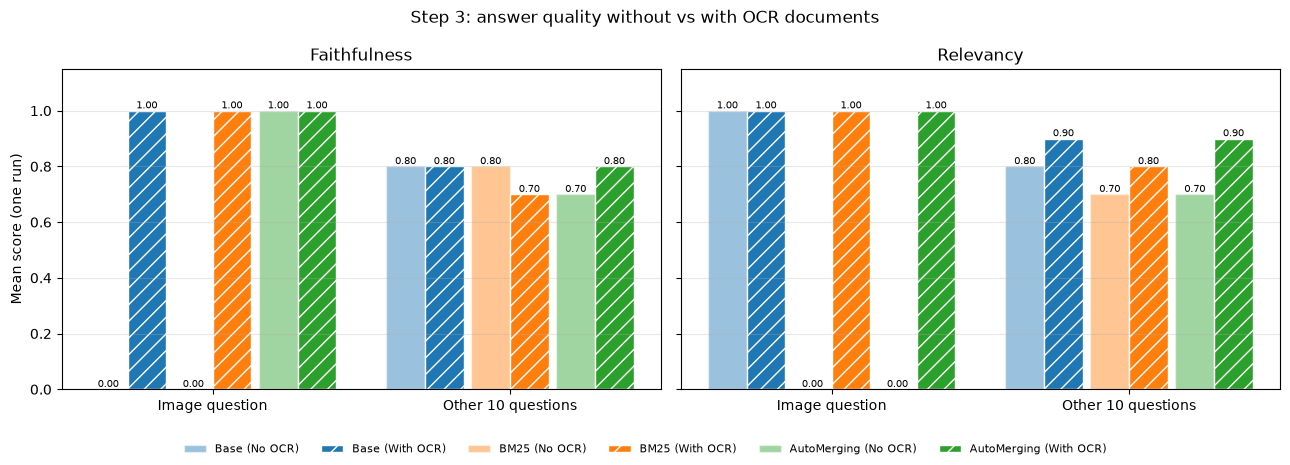

In [42]:
if step3_results is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    retr_names = ["Base", "BM25", "AutoMerging"]
    subsets = ["Image question", "Other 10 questions"]
    width = 0.13
    for ax, metric in zip(axes, ["Faithfulness", "Relevancy"]):
        for j, subset in enumerate(subsets):
            for i, r in enumerate(retr_names):
                for k, cond in enumerate(["No OCR", "With OCR"]):
                    v = step3_results.query("Subset == @subset and Retriever == @r and Condition == @cond")[metric].mean()
                    pos = j + (i - 1) * 2.2 * width + (k - 0.5) * width
                    bar = ax.bar(pos, v, width, color=f"C{i}", alpha=0.45 if cond == "No OCR" else 1.0,
                                 hatch="" if cond == "No OCR" else "//", edgecolor="white",
                                 label=f"{r} ({cond})" if j == 0 else None)
                    ax.bar_label(bar, fmt="%.2f", fontsize=7)
        ax.set_xticks(range(len(subsets)), subsets)
        ax.set_title(metric)
        ax.set_ylim(0, 1.15)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("Mean score (one run)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8, frameon=False)
    fig.suptitle("Step 3: answer quality without vs with OCR documents")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig("figures/step3_ocr_impact.png", dpi=150, bbox_inches="tight")
    plt.show()


In [43]:
if step3_results is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    # Before/after example for the image-only question, for every retriever
    for r in ["Base", "BM25", "AutoMerging"]:
        ex = step3_results.query("Question == @image_q and Retriever == @r").set_index("Condition")
        for cond in ["No OCR", "With OCR"]:
            print(f"=== {r} | {cond} (Faithfulness={ex.loc[cond, 'Faithfulness']}, Relevancy={ex.loc[cond, 'Relevancy']}) ===")
            print(ex.loc[cond, "Response"], "\n")
    print("Expected:", test_set.loc[test_set["Question"] == image_q, "Expected"].iloc[0])
    display(step3_results.pivot_table(index="Category", columns=["Retriever", "Condition"], values="Faithfulness",
                                      sort=False).reindex(CATEGORY_ORDER).round(2))


=== Base | No OCR (Faithfulness=0.0, Relevancy=1.0) ===
Migraines typically progress through four stages, although not everyone experiences all of them or in the same order. The duration of each stage can vary:

1. **Prodrome**: This stage occurs hours to days before the migraine and may include symptoms like mood changes, food cravings, and increased yawning. It can last from a few hours to a couple of days.

2. **Aura**: This visual disturbance stage can occur before or during the headache. It may include seeing flashing lights, zigzag lines, or blind spots. It usually lasts 20 to 60 minutes.

3. **Headache**: The headache phase is the most painful and can last from 4 to 72 hours. It's often described as pulsating pain on one side of the head, with moderate to severe intensity.

4. **Postdrome**: After the headache, some people experience a period of fatigue, weakness, or confusion, which can last for hours to days. 

=== Base | With OCR (Faithfulness=1.0, Relevancy=1.0) ===
The four

Retriever,AutoMerging,Base,BM25,AutoMerging,BM25,Base
Condition,No OCR,No OCR,No OCR,With OCR,With OCR,With OCR
Category,,,,,,
Semantic,1.0,1.0,1.0,1.0,0.5,1.0
Keyword,1.0,1.0,1.0,1.0,1.0,1.0
Multi-Chunk,0.5,1.0,1.0,0.5,1.0,0.5
Structured/Multimedia,1.0,0.5,0.5,1.0,1.0,1.0
Out-of-Scope,0.0,0.0,0.0,0.0,0.0,0.0
Numeric Precision,1.0,1.0,1.0,1.0,1.0,1.0
Ambiguous/Hints,0.0,0.0,0.0,1.0,0.0,1.0


In [44]:
if step3_results is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    # Hand check: refusals, and answers that claim more than the document says, with OCR
    hc = step3_results.query("Condition == 'With OCR' and Category in ['Out-of-Scope', 'Ambiguous/Hints']")
    displayify_df(hc.pivot(index=["Category", "Question"], columns="Retriever", values="Response"))


,Retriever,AutoMerging,BM25,Base
Category,Question,,,
Ambiguous/Hints,"Is chronic migraine genetic, and will I pass it on to my children?","Migraine can have a genetic component, as it tends to run in families. If you have a family history of migraine, such as your parents, there's a higher chance that your children might inherit a tendency to develop migraines. However, it's important to note that even if you have a family history of migraine, it doesn't mean your children will definitely develop them. Other factors, such as environmental triggers and lifestyle, also play a role in migraine onset and frequency. It's always a good idea to discuss any genetic concerns with a healthcare provider.","Chronic migraine can have a genetic component, as it tends to run in families. However, it's not solely determined by genetics. Environmental factors and other health conditions can also play a role. It's possible to pass on a tendency to develop chronic migraine to your children, but it's not guaranteed. It's important to discuss your family history and any concerns about your children's health with your healthcare provider.","Migraines can have a genetic component, as they tend to run in families. In your case, both your parents have experienced migraines. However, having a family history of migraines doesn't guarantee that your children will inherit them. It's also important to note that environmental factors and lifestyle can play a role in triggering migraines. Therefore, while there's a possibility that your children may develop migraines, it's not certain. It's always a good idea to discuss any family health history concerns with a healthcare provider."
Out-of-Scope,How much does a VYEPTI infusion cost per dose with insurance?,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or your healthcare provider's billing department for an estimate of your out-of-pocket costs. You can also call 1-833-4-VYEPTI (833-489-3784) for more information.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and location. It's best to contact your insurance provider or healthcare provider for the most accurate and up-to-date information on the cost of VYEPTI with your insurance coverage.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or healthcare provider for personalized information about the cost.


### 3.6 Analysis: with vs without OCR

**Answer quality (11 Step 1 questions, one run per condition; one question is about 9 points)**

| Retriever | Faithfulness: no OCR | Faithfulness: with OCR | Relevancy: no OCR | Relevancy: with OCR | Image question (F / R): no OCR → with OCR |
|---|---|---|---|---|---|
| Base | 0.727 | 0.818 | 0.818 | 0.909 | 0 / 1 → 1 / 1 |
| BM25 | 0.727 | 0.727 | 0.636 | 0.818 | 0 / 0 → 1 / 1 |
| AutoMerging | 0.727 | 0.818 | 0.636 | 0.909 | 1 / 0 → 1 / 1 |

**Retrieval on the 264 pooled text questions (3.4)**

| Retriever | Hit Rate: no OCR | Hit Rate: with OCR | MRR: no OCR | MRR: with OCR | Questions lost |
|---|---|---|---|---|---|
| Base | 0.924 | 0.905 | 0.841 | 0.804 | 5 |
| BM25 | 0.875 | 0.867 | 0.789 | 0.784 | 2 |
| AutoMerging | 0.928 | 0.909 | 0.849 | 0.818 | 5 |

**The image question is fixed.** Without OCR, the four stages exist only as pixels. Base and AutoMerging retrieved the three headache table rows, and BM25 retrieved unrelated text. All three answered from general knowledge, for example "aura usually lasts 20 to 60 minutes" instead of the graphic's "five to 60 minutes". The judge gave AutoMerging faithfulness 1 here, but by hand none of the three answers had the document's durations. With OCR, the *Migraine Stages* chunk ranks first for all three retrievers. All three answers then match the expected answer exactly, and each scores 1 / 1.

**The other 10 questions stay within noise.** Their averages move by at most two questions per retriever, mostly upward (for example Base faithfulness 0.8 → 0.8, AutoMerging relevancy 0.7 → 0.9). I did find one real harm by hand. On the sleep question (*"according to the different sections of the document"*), Base and AutoMerging with OCR retrieved the OCR text of the cover and contents page, because it lists the section names. Their whole context was 369 characters. Both answers then guessed what the "Living Healthy (page 16)" section says, and both scored faithfulness 0.

**Retrieval drops a little, and I kept all OCR documents.** On the pooled text questions, Hit Rate falls by about 2 points for Base and AutoMerging and by 1 point for BM25. The diagnostic in 3.4 shows the OCR chunks that take these slots come from pages 1, 2, 3, 5, 6, 7 and 8, not only from the cover and contents page. So dropping pages 1 and 2 would not remove the loss. The content-page OCR also carries the section headings and the *Lizzy's Tips* box, which the text layer lost. I kept all 8 OCR documents and treat this as a trade-off: one question that no retriever could answer before is now answered by all three, for a small, measured drop on text questions.

**Limits:** one run per condition, 11 questions and binary judges. The judge can be wrong in both directions, as the AutoMerging image answer shows.


## Step 4: Hybrid Retrieval (vector + BM25)
Everything here runs on the **final ingestion pipeline**: the layout-aware text and table rows from Step 2 plus the OCR documents from Step 3, with 256-token chunks and overlap 64 (`nodes_ocr`).

**Implementation**:
1. Separate vector and BM25 retrievers, each returning **`FUSION_CANDIDATES = 10`** results, so the fusion has more to work with than the final 3.
2. `QueryFusionRetriever(mode="relative_score", retriever_weights=[0.6, 0.4])`. Each list's scores are min-max scaled to [0, 1] and multiplied by its weight, and a chunk found by both retrievers gets the sum. The weights only take effect in `relative_score` / `dist_based_score` mode.
3. `num_queries=1`: no LLM-generated query variants, since that would be multi-query expansion, not hybrid retrieval.
4. `similarity_top_k=TOP_K` (3): the same final k as every other retriever.

In [45]:
from llama_index.core.retrievers import QueryFusionRetriever

FUSION_CANDIDATES = 10
VECTOR_WEIGHT, BM25_WEIGHT = 0.6, 0.4

def make_hybrid(nodes, weights=(VECTOR_WEIGHT, BM25_WEIGHT), top_k=TOP_K, candidates=FUSION_CANDIDATES):
    vector = VectorStoreIndex(nodes, embed_model=embed_model).as_retriever(similarity_top_k=candidates)
    bm25 = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=candidates,
                                       stemmer=Stemmer.Stemmer("english"), language="english")
    return QueryFusionRetriever([vector, bm25], retriever_weights=list(weights), mode="relative_score",
                                similarity_top_k=top_k, num_queries=1, use_async=False)

hybrid_retriever = make_hybrid(nodes_ocr)
hybrid_query_engine = RetrieverQueryEngine.from_args(hybrid_retriever)
final_retrievers = {**retr_ocr, "Hybrid": hybrid_retriever}           # Base, BM25, AutoMerging (fixed), Hybrid
final_engines = {**eng_ocr, "Hybrid": hybrid_query_engine}

for n in hybrid_retriever.retrieve(image_q):
    print(f"{n.score:.3f}  p{n.node.metadata['page_label']} [{n.node.metadata['source']}] {n.node.get_content()[:80]!r}")


1.000  p5 [ocr] 'Migraine Stages\nProdrome: few hours to a few days\nAura: five to 60 minutes\nHeada'
0.514  p5 [table] 'Headache Type: Migraine. Location: Unilateral. Type of Pain: Pulsating. Intensit'
0.323  p5 [table] 'Headache Type: Cluster. Location: Unilateral. Type of Pain: Orbital, supraorbita'


### 4.1 Retrieval metrics for all four retrievers
**Evaluation sets:**
* **Final synthetic set:** the `generate_question_context_pairs` dataset of the final Step 2 chunks. Text chunks keep the same deterministic IDs when the OCR documents are added, so their questions stay valid. Questions generated from the 8 new OCR chunks are added on top when the API is available.
* **Pooled set:** the 264 ablation questions from Step 2, a larger, more stable measure.

**Relevance:** the text-overlap test from 2.5, because AutoMerging returns parent nodes whose IDs never match the dataset. Each question has one source chunk, so Recall@3 = Hit Rate. With overlap 64, an overlapping neighbour or a merged parent can also count toward Precision@3. The next cell runs the standard ID-based `RetrieverEvaluator` for the three retrievers where IDs are meaningful (Base, BM25, Hybrid) and prints how far the two methods differ.

In [46]:
def try_dataset(name, nodes):
    """Cached synthetic dataset, or None if it isn't cached and the LLM is unavailable."""
    if os.path.exists(f"datasets/{name}.json") or LLM_AVAILABLE:
        return get_dataset(name, nodes)
    print(f"datasets/{name}.json not cached and LLM unavailable: evaluating without it")
    return None

text_node_ids = {n.node_id for n in final_nodes}
assert text_node_ids <= {n.node_id for n in nodes_ocr}, "text chunks must keep their ids when OCR docs are added"
final_qset = question_set(get_dataset(optimized_name, final_nodes))
ocr_nodes = [n for n in nodes_ocr if n.node_id not in text_node_ids]
ocr_ds = try_dataset("final_ocr_nodes", ocr_nodes)
ocr_qset = question_set(ocr_ds) if ocr_ds is not None else []
final_qset_all = final_qset + ocr_qset
print(f"Final synthetic set: {len(final_qset)} text-chunk questions + {len(ocr_qset)} OCR-chunk questions; "
      f"pooled set: {len(pooled_qset)} questions")

rows = []
for name, r in final_retrievers.items():
    rows.append({"Retriever": name, "Set": "Final synthetic", **retrieval_report(r, final_qset_all)})
    rows.append({"Retriever": name, "Set": "Pooled (264)", **retrieval_report(r, pooled_qset)})
step4_retrieval = pd.DataFrame(rows).set_index(["Set", "Retriever"]).sort_index(level=0, sort_remaining=False)
display(step4_retrieval.round(3))


Final synthetic set: 36 text-chunk questions + 8 OCR-chunk questions; pooled set: 264 questions


Hit Rate    MRR  Precision  Recall
Set             Retriever                                      
Final synthetic Base            0.864  0.746      0.288   0.864
                BM25            0.886  0.777      0.295   0.886
                AutoMerging     0.909  0.811      0.311   0.909
                Hybrid          0.909  0.852      0.303   0.909
Pooled (264)    Base            0.905  0.804      0.338   0.905
                BM25            0.867  0.784      0.336   0.867
                AutoMerging     0.909  0.818      0.316   0.909
                Hybrid          0.939  0.870      0.362   0.939

In [47]:
# Standard id-based RetrieverEvaluator as a cross-check (not defined for AutoMerging, see above)
id_ds = EmbeddingQAFinetuneDataset(
    queries={**get_dataset(optimized_name, final_nodes).queries, **(ocr_ds.queries if ocr_ds else {})},
    corpus={**get_dataset(optimized_name, final_nodes).corpus, **(ocr_ds.corpus if ocr_ds else {})},
    relevant_docs={**get_dataset(optimized_name, final_nodes).relevant_docs, **(ocr_ds.relevant_docs if ocr_ds else {})})
id_rows = []
for name in ["Base", "BM25", "Hybrid"]:
    ev = RetrieverEvaluator.from_metric_names(["hit_rate", "mrr", "precision", "recall"], retriever=final_retrievers[name])
    res = asyncio.run(ev.aevaluate_dataset(id_ds, workers=4))
    id_rows.append({"Retriever": name, **pd.DataFrame([r.metric_vals_dict for r in res]).mean().to_dict()})
id_df = pd.DataFrame(id_rows).set_index("Retriever")
print(f"Exact-id metrics on the final synthetic set ({len(id_ds.queries)} questions):")
display(id_df.round(3))
text_df = step4_retrieval.loc["Final synthetic"].loc[["Base", "BM25", "Hybrid"]]
gap = max(abs(id_df["hit_rate"] - text_df["Hit Rate"]).max(), abs(id_df["mrr"] - text_df["MRR"]).max())
print(f"Largest difference between id-based and text-based Hit Rate/MRR (Base, BM25, Hybrid): {gap:.3f}")


Exact-id metrics on the final synthetic set (44 questions):


,hit_rate,mrr,precision,recall
Retriever,,,,
Base,0.864,0.746,0.288,0.864
BM25,0.886,0.777,0.295,0.886
Hybrid,0.909,0.852,0.303,0.909


Largest difference between id-based and text-based Hit Rate/MRR (Base, BM25, Hybrid): 0.000


### 4.2 How sensitive is the hybrid to its weights?
I started from weights 0.6 / 0.4 and swept the vector weight on the pooled questions to see how close that setting is to the best one. The evaluated hybrid keeps **0.6 / 0.4**.

In [48]:
sweep = []
for w in [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    rep = retrieval_report(make_hybrid(nodes_ocr, weights=(w, 1 - w)), pooled_qset)
    sweep.append({"Vector weight": w, "Hit Rate": rep["Hit Rate"], "MRR": rep["MRR"]})
sweep_df = pd.DataFrame(sweep).set_index("Vector weight")
display(sweep_df.round(3).T)


Vector weight,0.0,0.2,0.4,0.5,0.6,0.8,1.0
Hit Rate,0.867,0.898,0.936,0.939,0.939,0.913,0.905
MRR,0.784,0.812,0.848,0.861,0.870,0.835,0.804


### 4.3 Answer quality for all four retrievers
Base, BM25 and AutoMerging on the final pipeline are the **"With OCR"** engines from Step 3, so their answers are reused. Only the hybrid engine is run here.

In [49]:
hybrid_answers = asyncio.run(run_evaluation({"Hybrid": hybrid_query_engine}, test_set, "results/step4_hybrid.csv",
                                            show_table=False))
if step3_results is None or hybrid_answers is None:
    step4_answers = None
else:
    step4_answers = pd.concat([step3_results.query("Condition == 'With OCR'")
                               .drop(columns=["Condition", "Run", "Subset"], errors="ignore"),
                               hybrid_answers], ignore_index=True)


results/step4_hybrid.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
Hybrid Retriever: 0.9091

✅ Relevancy Comparison
Hybrid Retriever: 0.7273


In [50]:
if step4_answers is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    overall4 = step4_answers.groupby("Retriever", sort=False)[["Faithfulness", "Relevancy"]].mean()
    display(overall4.join(step4_retrieval.loc["Pooled (264)"][["Hit Rate", "MRR"]]).round(3))
    display(step4_answers.pivot_table(index="Category", columns="Retriever", values=["Faithfulness", "Relevancy"],
                                      sort=False).reindex(CATEGORY_ORDER).round(2))


,Faithfulness,Relevancy,Hit Rate,MRR
Retriever,,,,
AutoMerging,0.818,0.909,0.909,0.818
BM25,0.727,0.818,0.867,0.784
Base,0.818,0.909,0.905,0.804
Hybrid,0.909,0.727,0.939,0.870


Faithfulness                    Relevancy            \
Retriever              AutoMerging BM25 Base Hybrid AutoMerging BM25 Base   
Category                                                                    
Semantic                       1.0  0.5  1.0    1.0         1.0  1.0  1.0   
Keyword                        1.0  1.0  1.0    1.0         1.0  1.0  1.0   
Multi-Chunk                    0.5  1.0  0.5    1.0         1.0  1.0  1.0   
Structured/Multimedia          1.0  1.0  1.0    1.0         1.0  1.0  1.0   
Out-of-Scope                   0.0  0.0  0.0    0.0         0.0  0.0  0.0   
Numeric Precision              1.0  1.0  1.0    1.0         1.0  1.0  1.0   
Ambiguous/Hints                1.0  0.0  1.0    1.0         1.0  0.0  1.0   

                              
Retriever             Hybrid  
Category                      
Semantic                 1.0  
Keyword                  1.0  
Multi-Chunk              0.5  
Structured/Multimedia    1.0  
Out-of-Scope             0.0  
Numeric Precision        1.0  
Ambiguous/Hints          0.0

### 4.4 Visual summary

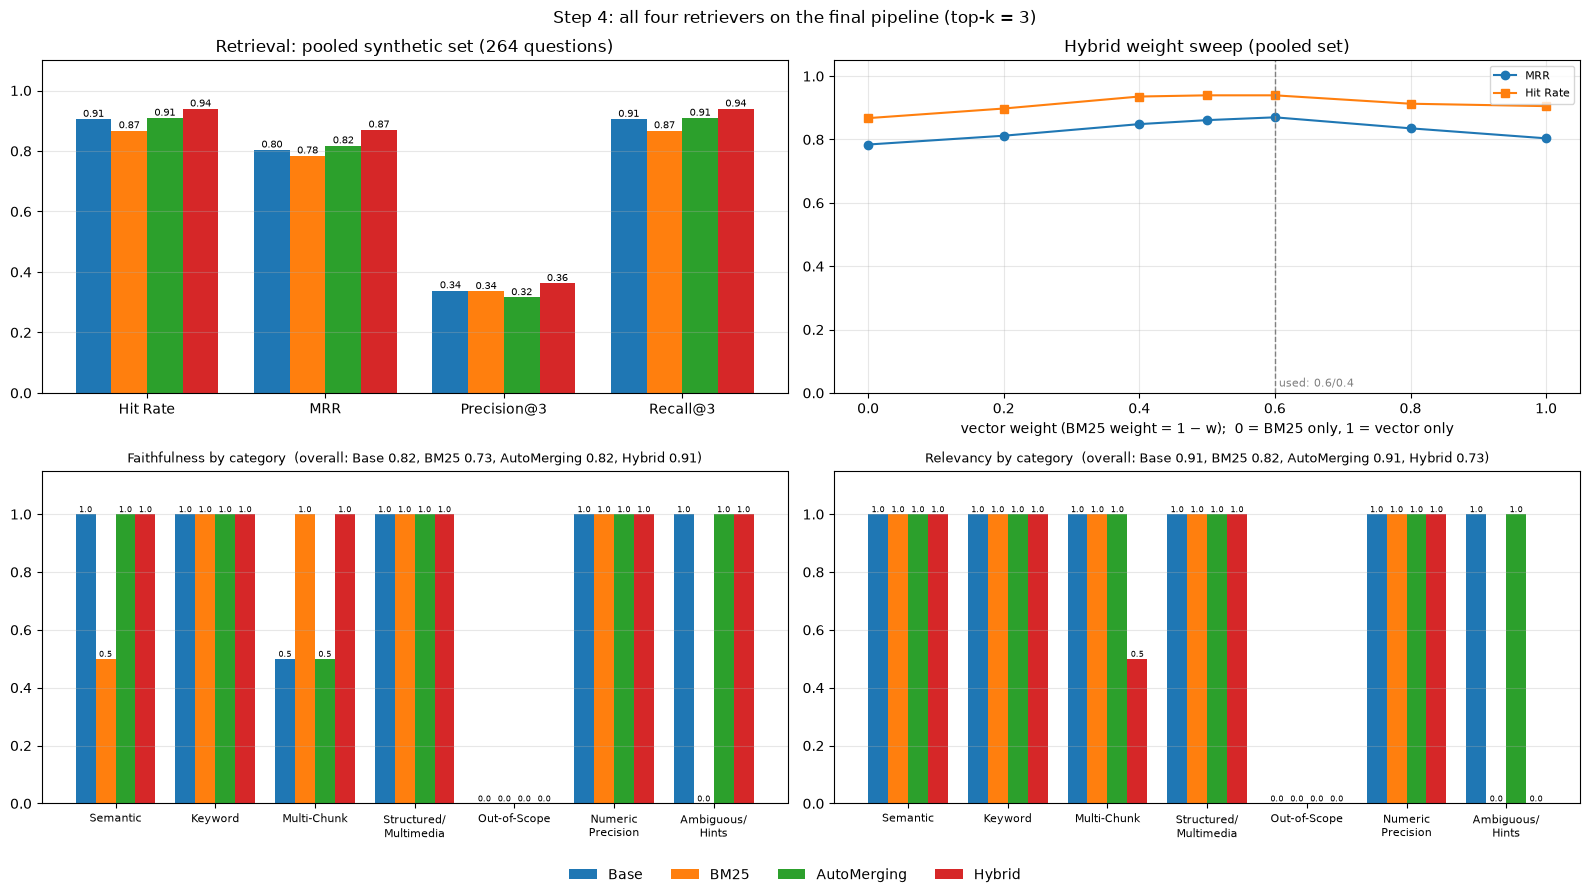

In [51]:
ORDER4 = ["Base", "BM25", "AutoMerging", "Hybrid"]
have_answers = step4_answers is not None
fig = plt.figure(figsize=(16, 9 if have_answers else 4.5))
gs = fig.add_gridspec(2 if have_answers else 1, 2)

ax = fig.add_subplot(gs[0, 0])
mets = ["Hit Rate", "MRR", "Precision", "Recall"]
for i, r in enumerate(ORDER4):
    vals = step4_retrieval.loc[("Pooled (264)", r), mets].astype(float)
    bars = ax.bar(np.arange(4) + (i - 1.5) * 0.2, vals, 0.2, label=r, color=f"C{i}")
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(range(4), ["Hit Rate", "MRR", "Precision@3", "Recall@3"])
ax.set_ylim(0, 1.1); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"Retrieval: pooled synthetic set ({len(pooled_qset)} questions)")

ax = fig.add_subplot(gs[0, 1])
ax.plot(sweep_df.index, sweep_df["MRR"], "o-", label="MRR")
ax.plot(sweep_df.index, sweep_df["Hit Rate"], "s-", label="Hit Rate")
ax.axvline(VECTOR_WEIGHT, color="gray", ls="--", lw=1)
ax.text(VECTOR_WEIGHT, 0.02, " used: 0.6/0.4", fontsize=8, color="gray")
ax.set_xlabel("vector weight (BM25 weight = 1 − w);  0 = BM25 only, 1 = vector only")
ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Hybrid weight sweep (pooled set)")

if have_answers:
    cats = [c for c in CATEGORY_ORDER if c in set(step4_answers["Category"])]
    for col, metric in enumerate(["Faithfulness", "Relevancy"]):
        ax = fig.add_subplot(gs[1, col])
        piv = step4_answers.pivot_table(index="Category", columns="Retriever", values=metric).reindex(cats)
        for i, r in enumerate(ORDER4):
            bars = ax.bar(np.arange(len(cats)) + (i - 1.5) * 0.2, piv[r], 0.2, color=f"C{i}", label=r)
            ax.bar_label(bars, fmt="%.1f", fontsize=6)
        ax.set_xticks(range(len(cats)), [c.replace("/", "/\n").replace(" ", "\n") for c in cats], fontsize=8)
        ax.set_ylim(0, 1.15); ax.grid(axis="y", alpha=0.3)
        means = step4_answers.groupby("Retriever")[metric].mean()
        ax.set_title(f"{metric} by category  (overall: " + ", ".join(f"{r} {means[r]:.2f}" for r in ORDER4) + ")",
                     fontsize=9)
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Step 4: all four retrievers on the final pipeline (top-k = 3)")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("figures/step4_summary.png", dpi=150, bbox_inches="tight")
plt.show()


### 4.5 Retrieval metrics on both synthetic sets
The final synthetic set is the main synthetic dataset; the pooled set is the larger cross-check.

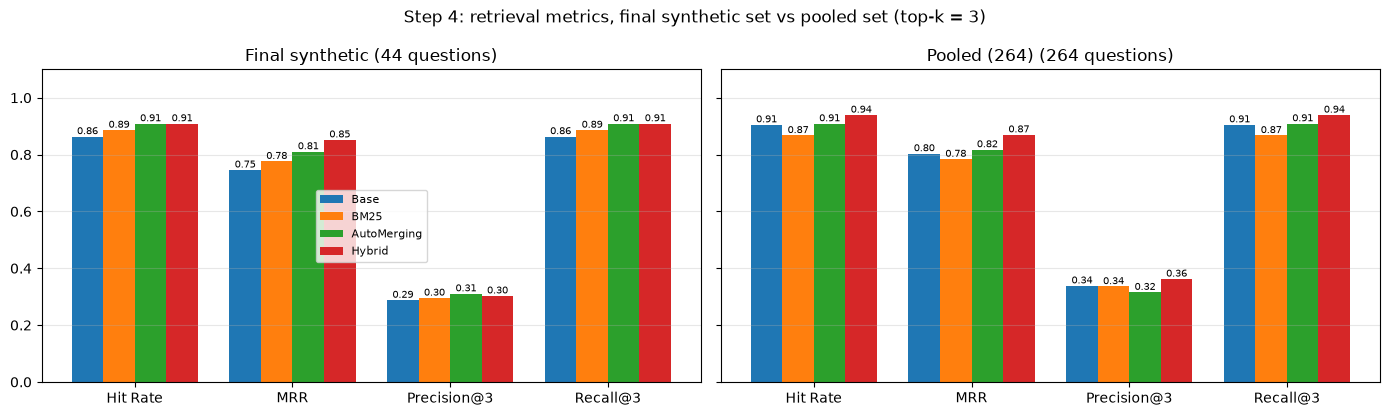

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
mets = ["Hit Rate", "MRR", "Precision", "Recall"]
for ax, s in zip(axes, ["Final synthetic", "Pooled (264)"]):
    for i, r in enumerate(ORDER4):
        vals = step4_retrieval.loc[(s, r), mets].astype(float)
        bars = ax.bar(np.arange(4) + (i - 1.5) * 0.2, vals, 0.2, label=r, color=f"C{i}")
        ax.bar_label(bars, fmt="%.2f", fontsize=7)
    n_q = len(final_qset_all) if s == "Final synthetic" else len(pooled_qset)
    ax.set_xticks(range(4), ["Hit Rate", "MRR", "Precision@3", "Recall@3"])
    ax.set_title(f"{s} ({n_q} questions)"); ax.set_ylim(0, 1.1); ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Step 4: retrieval metrics, final synthetic set vs pooled set (top-k = 3)")
fig.tight_layout()
fig.savefig("figures/step4_retrieval_both_sets.png", dpi=150, bbox_inches="tight")
plt.show()


In [53]:
if step4_answers is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    # Hand check of the adversarial questions for all four retrievers
    hc4 = step4_answers[step4_answers["Category"].isin(["Out-of-Scope", "Ambiguous/Hints"])]
    displayify_df(hc4.pivot(index=["Category", "Question"], columns="Retriever", values="Response"))


,Retriever,AutoMerging,BM25,Base,Hybrid
Category,Question,,,,
Ambiguous/Hints,"Is chronic migraine genetic, and will I pass it on to my children?","Migraine can have a genetic component, as it tends to run in families. If you have a family history of migraine, such as your parents, there's a higher chance that your children might inherit a tendency to develop migraines. However, it's important to note that even if you have a family history of migraine, it doesn't mean your children will definitely develop them. Other factors, such as environmental triggers and lifestyle, also play a role in migraine onset and frequency. It's always a good idea to discuss any genetic concerns with a healthcare provider.","Chronic migraine can have a genetic component, as it tends to run in families. However, it's not solely determined by genetics. Environmental factors and other health conditions can also play a role. It's possible to pass on a tendency to develop chronic migraine to your children, but it's not guaranteed. It's important to discuss your family history and any concerns about your children's health with your healthcare provider.","Migraines can have a genetic component, as they tend to run in families. In your case, both your parents have experienced migraines. However, having a family history of migraines doesn't guarantee that your children will inherit them. It's also important to note that environmental factors and lifestyle can play a role in triggering migraines. Therefore, while there's a possibility that your children may develop migraines, it's not certain. It's always a good idea to discuss any family health history concerns with a healthcare provider.","Chronic migraine can have a genetic component, as it tends to run in families. However, it's not solely determined by genetics. Environmental factors and lifestyle also play a significant role. While you may have a higher chance of passing on a tendency to develop migraines to your children, it's not guaranteed. It's important to note that even if your children inherit this tendency, it doesn't mean they will definitely develop chronic migraines. Regular check-ups and open communication with healthcare providers can help manage and monitor any potential migraine symptoms in your children."
Out-of-Scope,How much does a VYEPTI infusion cost per dose with insurance?,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or your healthcare provider's billing department for an estimate of your out-of-pocket costs. You can also call 1-833-4-VYEPTI (833-489-3784) for more information.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and location. It's best to contact your insurance provider or healthcare provider for the most accurate and up-to-date information on the cost of VYEPTI with your insurance coverage.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or healthcare provider for personalized information about the cost.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or your healthcare provider's office for an estimate of your out-of-pocket cost.


### 4.6 Analysis: all four retrievers

**Results (final pipeline with OCR, final k = 3 for every retriever)**

| Retriever | Faithfulness | Relevancy | Pooled Hit Rate | Pooled MRR | Pooled Precision@3 | Final-set MRR (44 q) |
|---|---|---|---|---|---|---|
| Base | 0.818 | 0.909 | 0.905 | 0.804 | 0.338 | 0.746 |
| BM25 | 0.727 | 0.818 | 0.867 | 0.784 | 0.336 | 0.777 |
| AutoMerging | 0.818 | 0.909 | 0.909 | 0.818 | 0.316 | 0.811 |
| **Hybrid (0.6 / 0.4)** | **0.909** | 0.727 | **0.939** | **0.870** | **0.362** | **0.852** |

**The hybrid retrieves best.** It has the highest Hit Rate, MRR and Precision@3 on both question sets. BM25 and the vector retriever miss different questions. BM25 wins when the question repeats the document's exact words, such as table column names or drug names. The vector retriever wins when the wording is different. Fusion keeps both kinds of hits. The weight sweep (4.2) shows this too: BM25 alone has MRR 0.784, the vector retriever alone 0.804, and the mix peaks at 0.870 at weight 0.6. Weight 0.5 is almost as good (0.861), so the suggested 0.6 / 0.4 was the best setting I tested, and the result is not sensitive near the middle. The ID-based `RetrieverEvaluator` gives the same numbers as my text-overlap test (largest gap 0.000).

**Answer quality does not show the same order, and the gaps are 1-2 questions.** The hybrid has the highest faithfulness (0.909) but the lowest relevancy (0.727). Its relevancy loss comes from two questions, which I checked by hand:
* *Sleep (Multi-Chunk):* the hybrid's answer is the most complete of the four. It covers the sleep disorders on page 6 and the app study on page 3. The judge still gave relevancy 0, which looks wrong. Base and AutoMerging got only the contents-page OCR chunk for this question and made up content (faithfulness 0, see 3.6). The hybrid also got that chunk, but its other two slots held the right text.
* *Genetics (Ambiguous/Hints):* the hybrid claims migraine "has a genetic component", which the document never says. The judge gave faithfulness 1, which is wrong by hand check.

**Out-of-Scope (hand-checked):** all four retrievers deflected the VYEPTI price question to the insurer. None invented a price, but none said the document does not have the answer.

**Conclusion:** I take the hybrid as the best Step 4 setup. On 11 questions the answer scores differ by 1-2 questions, which is within noise and includes judge mistakes in both directions. The retrieval metrics on 264 questions are the more reliable signal, and there the hybrid is ahead on every metric.


## Step 5: Making the RAG Even Better
Each change is measured against the **best Step 4 setup** (the retriever with the highest pooled MRR), one change at a time: retrieval changes on the synthetic sets, and every change on answer quality with the Step 1 questions.

| # | Improvement | Bottleneck it targets |
|---|---|---|
| A | **Cross-encoder re-ranking** of the top 10 candidates down to 3 | Precision: the vector retriever and BM25 each rank by a single similarity score |
| B | **Section headers from OCR** added to every chunk | Chunks lose their context: *"it should bring improvements in four areas"* does not say it is about treatment |
| C | **Strict "answer only from the document" prompt** | Generation: in Steps 1 and 3 every retriever claimed a "genetic component" and deflected the price question instead of saying the document has no answer |

B uses the headings that only OCR recovered (Step 3). C changes only the generation step, so it is judged on answer quality, with a hand check.

In [54]:
from llama_index.core.schema import MetadataMode

BEST4 = step4_retrieval.loc["Pooled (264)"]["MRR"].idxmax()
print("Best Step 4 setup (pooled MRR):", BEST4)
display(step4_retrieval.loc["Pooled (264)"].round(3))

def make_retriever(kind, docs, nodes, k=TOP_K):
    """Any of the four Step 4 retrievers over a given ingestion, returning k results."""
    if kind == "Base":
        return VectorStoreIndex(nodes, embed_model=embed_model).as_retriever(similarity_top_k=k)
    if kind == "BM25":
        return BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=k,
                                           stemmer=Stemmer.Stemmer("english"), language="english")
    if kind == "Hybrid":
        return make_hybrid(nodes, top_k=k, candidates=max(FUSION_CANDIDATES, k))
    if kind == "AutoMerging":
        h_nodes = HierarchicalNodeParser.from_defaults(chunk_sizes=[1024, 512, CHOSEN_CS],
                                                       chunk_overlap=best_ov).get_nodes_from_documents(docs)
        storage = StorageContext.from_defaults()
        storage.docstore.add_documents(h_nodes)
        leaves = VectorStoreIndex(get_leaf_nodes(h_nodes), storage_context=storage, embed_model=embed_model)
        return AutoMergingRetriever(leaves.as_retriever(similarity_top_k=k), storage)
    raise ValueError(kind)

def score_retrieval(retriever):
    pooled, final = retrieval_report(retriever, pooled_qset), retrieval_report(retriever, final_qset_all)
    return {"Pooled Hit Rate": pooled["Hit Rate"], "Pooled MRR": pooled["MRR"], "Pooled Precision": pooled["Precision"],
            "Final Hit Rate": final["Hit Rate"], "Final MRR": final["MRR"]}

best4_retriever = final_retrievers[BEST4]
t5_rows = [{"Variant": f"Step 4 best ({BEST4})", **score_retrieval(best4_retriever)}]


Best Step 4 setup (pooled MRR): Hybrid


,Hit Rate,MRR,Precision,Recall
Retriever,,,,
Base,0.905,0.804,0.338,0.905
BM25,0.867,0.784,0.336,0.867
AutoMerging,0.909,0.818,0.316,0.909
Hybrid,0.939,0.870,0.362,0.939


### 5.1 Improvement A: cross-encoder re-ranking
The best retriever returns **10 candidates**; a cross-encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) scores each *(question, chunk)* pair jointly, and I keep the top **3**, so the final k is unchanged. The vector retriever compares two separately computed embeddings, while the cross-encoder reads the question and the chunk together, which is slower but more precise.

In [55]:
from llama_index.core.postprocessor import SentenceTransformerRerank
from llama_index.core.retrievers import BaseRetriever

RERANK_CANDIDATES = 10
reranker = SentenceTransformerRerank(model="cross-encoder/ms-marco-MiniLM-L-6-v2", top_n=TOP_K)

class RerankRetriever(BaseRetriever):
    """Retrieve a wide candidate set, then keep the cross-encoder's top_n."""
    def __init__(self, candidates, reranker):
        super().__init__()
        self._candidates, self._reranker = candidates, reranker
    def _retrieve(self, query_bundle):
        return self._reranker.postprocess_nodes(self._candidates.retrieve(query_bundle), query_bundle=query_bundle)

rerank_retriever = RerankRetriever(make_retriever(BEST4, docs_ocr, nodes_ocr, k=RERANK_CANDIDATES), reranker)
t5_rows.append({"Variant": "A: + cross-encoder re-rank", **score_retrieval(rerank_retriever)})
display(pd.DataFrame(t5_rows).set_index("Variant").round(3))


,Pooled Hit Rate,Pooled MRR,Pooled Precision,Final Hit Rate,Final MRR
Variant,,,,,
Step 4 best (Hybrid),0.939,0.870,0.362,0.909,0.852
A: + cross-encoder re-rank,0.947,0.892,0.356,0.864,0.807


In [56]:
# Measured cost of re-ranking: retrieval latency per query on the Step 1 questions (CPU)
import time
def ms_per_query(retriever, questions):
    t = time.perf_counter()
    for q in questions:
        retriever.retrieve(q)
    return (time.perf_counter() - t) / len(questions) * 1000

qs = test_set["Question"].tolist()
ms_per_query(rerank_retriever, qs[:1])                     # warm-up (model load)
print(f"{BEST4}: {ms_per_query(best4_retriever, qs):.0f} ms/query | "
      f"{BEST4} + re-rank: {ms_per_query(rerank_retriever, qs):.0f} ms/query")


Hybrid: 5 ms/query | Hybrid + re-rank: 49 ms/query


### 5.2 Improvement B: section headers recovered by OCR
A chunk such as *"Medication won't eliminate headache days, but it should bring improvements in four areas"* never says it is about treatment, and a table row never says it comes from a headache classification table. In the PDF that context is in the section headings, which the text layer lost (Step 2) and only OCR recovered (Step 3).

I gave every chunk a `section` metadata field built from its page's OCR headings (up to two mostly-uppercase lines, e.g. *TREATMENT SMARTS CHRONIC MIGRAINE / MANAGE YOUR CHRONIC MIGRAINE*); table rows get the table caption. LlamaIndex includes metadata in the text it embeds (`MetadataMode.EMBED`), and BM25 indexes the same text, so both retrievers see the heading while the chunk text stays the same.

In [57]:
def heading_lines(text, max_lines=2):
    """Mostly-uppercase OCR lines (section headings) of a page, minus the 'WebMD' masthead word."""
    out = []
    for line in text.split("\n"):
        letters = [c for c in line if c.isalpha()]
        if len(letters) >= 4 and sum(c.isupper() for c in letters) / len(letters) > 0.7:
            out.append(re.sub(r"^WebMD\s+", "", line).strip())
    return out[:max_lines]

page_heading = {}
for d in ocr_docs:
    lines = heading_lines(d.text) or d.text.split("\n")[:1]
    page_heading[d.metadata["page_label"]] = " / ".join(lines)[:120]
page_heading["9"] = page_heading.get("8", "") + " / " + page_heading.get("9", "")   # page 9 continues page 8's story
for p, h in sorted(page_heading.items(), key=lambda x: int(x[0])):
    print(f"page {p}: {h}")

def with_section(docs):
    """Copies of the documents with a 'section' metadata field (tables get their caption)."""
    out = []
    for d in docs:
        section = ("Table 1: Headache Types (International Headache Society classification)"
                   if d.metadata.get("source") == "table" else page_heading.get(d.metadata["page_label"], ""))
        out.append(Document(text=d.text, id_=d.id_, metadata={**d.metadata, "section": section}))
    return out

docs_hdr = with_section(docs_ocr)
nodes_hdr = build_nodes(docs_hdr, CHOSEN_CS, best_ov, **para_kw)
print(f"\n{len(nodes_hdr)} nodes. Example embedded text:\n")
print(next(n for n in nodes_hdr if n.metadata["page_label"] == "7").get_content(metadata_mode=MetadataMode.EMBED)[:400])

header_retriever = make_retriever(BEST4, docs_hdr, nodes_hdr)
t5_rows.append({"Variant": "B: + OCR section headers", **score_retrieval(header_retriever)})
display(pd.DataFrame(t5_rows).set_index("Variant").round(3))


page 1: REAL STORIES CHRONIC MIGRAINE / HEALTH SMARTS
page 2: CHRONIC MIGRAINE CONTENTS / INSIDE THE ISSUE
page 3: NEWS CHRONIC MIGRAINE / THE LATEST ON
page 5: Migraine Stages
page 6: HEALTH SMARTS CHRONIC MIGRAINE
page 7: TREATMENT SMARTS CHRONIC MIGRAINE / MANAGE YOUR CHRONIC MIGRAINE
page 8: CHRONIC MIGRAINE FIRST PERSON
page 9: CHRONIC MIGRAINE FIRST PERSON / LIZZY's TIPS

33 nodes. Example embedded text:

page_label: 7
source: text
section: TREATMENT SMARTS CHRONIC MIGRAINE / MANAGE YOUR CHRONIC MIGRAINE

By Sonya Collins Reviewed by Melinda Ratini, DO, MS, WebMD Medical Reviewer

hen you have chronic migraine, you’ll need medicine for relief during an attack and medicine to prevent future attacks. If your medicine isn’t working, don’t give up. There are more options available today than ever befor


,Pooled Hit Rate,Pooled MRR,Pooled Precision,Final Hit Rate,Final MRR
Variant,,,,,
Step 4 best (Hybrid),0.939,0.870,0.362,0.909,0.852
A: + cross-encoder re-rank,0.947,0.892,0.356,0.864,0.807
B: + OCR section headers,0.947,0.864,0.361,0.864,0.792


### 5.3 Improvement C: prompt that tells the model to say when the answer is not in the document
LlamaIndex's default QA prompt already says *"not prior knowledge"*, but Mistral-Nemo ignored it on the adversarial questions: it claimed migraine "has a genetic component" (not in the document) and deflected the price question. Prompt C states the rules explicitly, gives an exact sentence to use when the document has no answer, and adds rules for partial answers and for copying numbers exactly. Retrieval is the best Step 4 retriever, unchanged.

In [58]:
from llama_index.core import PromptTemplate

GROUNDED_QA = PromptTemplate("""You answer questions about one document: a WebMD magazine issue about chronic migraine.
Excerpts from the document:
---------------------
{context_str}
---------------------
Rules:
1. Use ONLY facts stated in the excerpts. Do not add general medical knowledge, even if you are confident it is true.
2. If the excerpts do not answer the question, reply: "The document does not provide this information." You may then \
name the closest related fact the excerpts do contain.
3. If the excerpts answer only part of the question, answer that part and say which part the document does not cover.
4. Copy numbers, durations, percentages and names exactly as written.

Question: {query_str}
Answer: """)

grounded_engine = RetrieverQueryEngine.from_args(best4_retriever, text_qa_template=GROUNDED_QA)
print(grounded_engine.get_prompts()["response_synthesizer:text_qa_template"].get_template()[:200], "...")


You answer questions about one document: a WebMD magazine issue about chronic migraine.
Excerpts from the document:
---------------------
{context_str}
---------------------
Rules:
1. Use ONLY facts s ...


### 5.4 Answer quality: one change at a time
The baseline rows are the best Step 4 retriever's answers from 4.3. Each variant is one run of the 11 questions.

In [59]:
t5_engines = {
    "A: + cross-encoder re-rank": RetrieverQueryEngine.from_args(rerank_retriever),
    "B: + OCR section headers": RetrieverQueryEngine.from_args(header_retriever),
    "C: + grounded prompt": grounded_engine,
}
t5_answer_runs = {}
for name, engine in t5_engines.items():
    path = "results/step5_" + re.sub(r"[^a-z]+", "_", name.lower()).strip("_") + ".csv"
    t5_answer_runs[name] = asyncio.run(run_evaluation({name: engine}, test_set, path, show_table=False))

if step4_answers is None or any(v is None for v in t5_answer_runs.values()):
    step5_answers = None
else:
    base_rows = step4_answers[step4_answers["Retriever"] == BEST4].assign(Retriever=f"Step 4 best ({BEST4})")
    step5_answers = pd.concat([base_rows, *t5_answer_runs.values()], ignore_index=True)


results/step5_a_cross_encoder_re_rank.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
A: + cross-encoder re-rank Retriever: 0.7273

✅ Relevancy Comparison
A: + cross-encoder re-rank Retriever: 0.6364
results/step5_b_ocr_section_headers.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
B: + OCR section headers Retriever: 0.7273

✅ Relevancy Comparison
B: + OCR section headers Retriever: 0.7273
results/step5_c_grounded_prompt.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
C: + grounded prompt Retriever: 1.0000

✅ Relevancy Comparison
C: + grounded prompt Retriever: 0.9091


In [60]:
ADVERSARIAL = ["Out-of-Scope", "Numeric Precision", "Ambiguous/Hints"]
t5_table = pd.DataFrame(t5_rows).set_index("Variant")
t5_table.loc["C: + grounded prompt"] = t5_table.loc[f"Step 4 best ({BEST4})"]   # retrieval unchanged by a prompt
if step5_answers is not None:
    ans = step5_answers.groupby("Retriever", sort=False)[["Faithfulness", "Relevancy"]].mean()
    adv = step5_answers[step5_answers["Category"].isin(ADVERSARIAL)].groupby("Retriever")["Faithfulness"].mean()
    t5_table = t5_table.join(ans).join(adv.rename("Adversarial Faithfulness"))
display(t5_table.round(3))


,Pooled Hit Rate,Pooled MRR,Pooled Precision,Final Hit Rate,Final MRR,Faithfulness,Relevancy,Adversarial Faithfulness
Variant,,,,,,,,
Step 4 best (Hybrid),0.939,0.870,0.362,0.909,0.852,0.909,0.727,0.667
A: + cross-encoder re-rank,0.947,0.892,0.356,0.864,0.807,0.727,0.636,0.333
B: + OCR section headers,0.947,0.864,0.361,0.864,0.792,0.727,0.727,0.333
C: + grounded prompt,0.939,0.870,0.362,0.909,0.852,1.000,0.909,1.000


In [61]:
if step5_answers is None:
    print('Skipped: needs answer-quality results. Add a working OPENROUTER_API_KEY and re-run the notebook.')
else:
    # Hand check: did the variants refuse correctly, or claim more than the document says?
    hc5 = step5_answers[step5_answers["Category"].isin(["Out-of-Scope", "Ambiguous/Hints"])]
    displayify_df(hc5.pivot(index=["Category", "Question"], columns="Retriever", values="Response"))


,Retriever,A: + cross-encoder re-rank,B: + OCR section headers,C: + grounded prompt,Step 4 best (Hybrid)
Category,Question,,,,
Ambiguous/Hints,"Is chronic migraine genetic, and will I pass it on to my children?","While there's no definitive proof that chronic migraine is solely genetic, research suggests a strong hereditary component. If one or both of your parents have migraines, you're more likely to develop them yourself. However, environmental factors also play a role. Therefore, while there's a chance you might pass on a tendency to develop migraines to your children, it's not guaranteed. It's always a good idea to discuss any family health history with a healthcare provider.","Migraine can have a genetic component, as it tends to run in families. However, it's not solely determined by genetics. Environmental factors and lifestyle also play a role. While you may have a higher chance of passing on a tendency to experience migraines to your children, it's not guaranteed. Each child is unique and may have a different susceptibility to migraines. It's important to remember that even if your children inherit this tendency, it doesn't mean they will definitely develop migraines.","The document does not provide information about whether chronic migraine is genetic or if it can be passed on to children. It only mentions that the author's parents both had migraines, but it does not discuss the inheritance pattern or likelihood of passing it on to their children.","Chronic migraine can have a genetic component, as it tends to run in families. However, it's not solely determined by genetics. Environmental factors and lifestyle also play a significant role. While you may have a higher chance of passing on a tendency to develop migraines to your children, it's not guaranteed. It's important to note that even if your children inherit this tendency, it doesn't mean they will definitely develop chronic migraines. Regular check-ups and open communication with healthcare providers can help manage and monitor any potential migraine symptoms in your children."
Out-of-Scope,How much does a VYEPTI infusion cost per dose with insurance?,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or healthcare provider for personalized information about the cost.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or healthcare provider for personalized information about the cost.,The document does not provide information about the cost of VYEPTI with insurance.,The cost of a VYEPTI infusion per dose with insurance can vary depending on your specific insurance plan and coverage. It's best to contact your insurance provider or your healthcare provider's office for an estimate of your out-of-pocket cost.


### 5.5 Final system: all kept improvements together
Keep rules, fixed before the results: a retrieval change (A, B) is kept if it raises pooled MRR; the prompt (C) is kept if it raises mean faithfulness without lowering relevancy by more than one question (0.09). If only one change is kept, the final system is that variant and reuses its run.

In [62]:
base_mrr = t5_table.loc[f"Step 4 best ({BEST4})", "Pooled MRR"]
keep_A = t5_table.loc["A: + cross-encoder re-rank", "Pooled MRR"] > base_mrr
keep_B = t5_table.loc["B: + OCR section headers", "Pooled MRR"] > base_mrr
keep_C = None
if step5_answers is not None:
    b, c = t5_table.loc[f"Step 4 best ({BEST4})"], t5_table.loc["C: + grounded prompt"]
    keep_C = bool(c["Faithfulness"] > b["Faithfulness"] and c["Relevancy"] >= b["Relevancy"] - 0.09)
print(f"Keep A (re-rank): {keep_A}   Keep B (headers): {keep_B}   Keep C (grounded prompt): {keep_C}")

f_docs, f_nodes = (docs_hdr, nodes_hdr) if keep_B else (docs_ocr, nodes_ocr)
final_retriever = (RerankRetriever(make_retriever(BEST4, f_docs, f_nodes, k=RERANK_CANDIDATES), reranker)
                   if keep_A else make_retriever(BEST4, f_docs, f_nodes))
final_engine = RetrieverQueryEngine.from_args(final_retriever, **({"text_qa_template": GROUNDED_QA} if keep_C else {}))
final_label = "Final: " + (" + ".join(x for x, k in [("A", keep_A), ("B", keep_B), ("C", keep_C)] if k) or "no change")
final_scores = score_retrieval(final_retriever)

kept = [x for x, k in [("A", keep_A), ("B", keep_B), ("C", keep_C)] if k]
variant_names = {"A": "A: + cross-encoder re-rank", "B": "B: + OCR section headers", "C": "C: + grounded prompt"}
if keep_C is None:                       # answer-quality runs not available yet
    final_answers = None
elif len(kept) == 0:                     # final = Step 4 best, already scored
    final_answers = step5_answers[step5_answers["Retriever"] == f"Step 4 best ({BEST4})"]
elif len(kept) == 1:                     # final = that single variant, already scored: no new calls
    final_answers = t5_answer_runs[variant_names[kept[0]]]
else:                                    # only a real combination costs API calls
    final_answers = asyncio.run(run_evaluation({final_label: final_engine}, test_set,
                                               f"results/step5_final_{''.join(kept)}.csv", show_table=False))
row = {**final_scores}
if final_answers is not None:
    row.update(final_answers[["Faithfulness", "Relevancy"]].mean().to_dict())
    row["Adversarial Faithfulness"] = final_answers[final_answers["Category"].isin(ADVERSARIAL)]["Faithfulness"].mean()
t5_table.loc[final_label] = pd.Series(row)
display(t5_table.round(3))


Keep A (re-rank): True   Keep B (headers): False   Keep C (grounded prompt): True


results/step5_final_AC.csv: 11 cached, 0 to run

✅ Faithfulness Comparison
Final: A + C Retriever: 0.9091

✅ Relevancy Comparison
Final: A + C Retriever: 1.0000


,Pooled Hit Rate,Pooled MRR,Pooled Precision,Final Hit Rate,Final MRR,Faithfulness,Relevancy,Adversarial Faithfulness
Variant,,,,,,,,
Step 4 best (Hybrid),0.939,0.870,0.362,0.909,0.852,0.909,0.727,0.667
A: + cross-encoder re-rank,0.947,0.892,0.356,0.864,0.807,0.727,0.636,0.333
B: + OCR section headers,0.947,0.864,0.361,0.864,0.792,0.727,0.727,0.333
C: + grounded prompt,0.939,0.870,0.362,0.909,0.852,1.000,0.909,1.000
Final: A + C,0.947,0.892,0.356,0.864,0.807,0.909,1.000,1.000


In [63]:
# Check the final system's one faithfulness 0: the judge sees only the 3 retrieved chunks, not the whole PDF
q = test_set.loc[test_set["Category"] == "Semantic", "Question"].iloc[0]
ctx = " ".join(n.node.get_content() for n in final_retriever.retrieve(q))
print(q)
for k in ["477", "several times", "2 weeks", "two weeks"]:
    print(f"{k!r:18} in retrieved context: {k in ctx}")


What can someone do in their day-to-day life to anticipate when a migraine attack might hit?
'477'              in retrieved context: True
'several times'    in retrieved context: True
'2 weeks'          in retrieved context: True
'two weeks'        in retrieved context: False


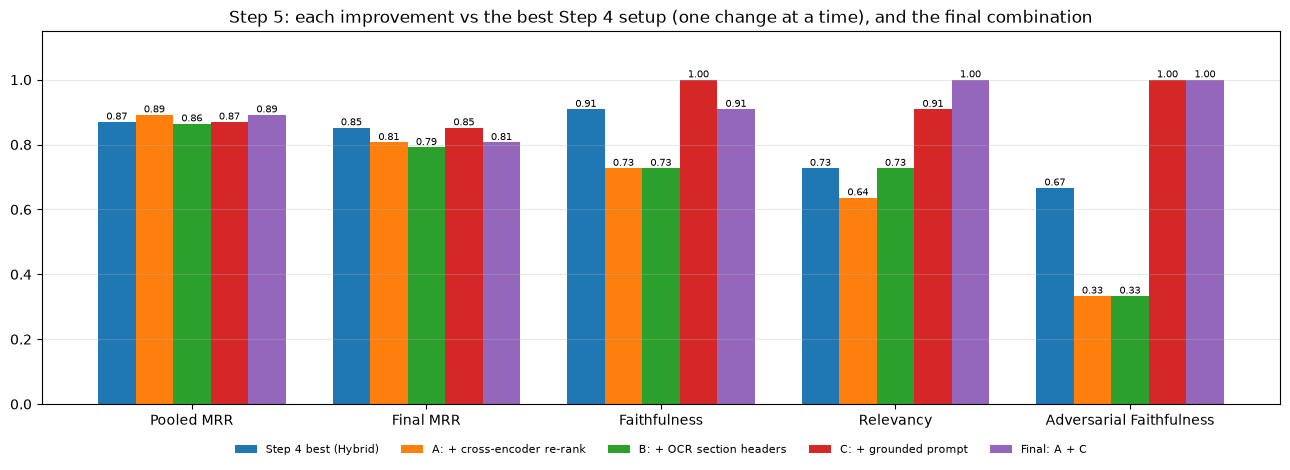

In [64]:
cols = [c for c in ["Pooled MRR", "Final MRR", "Faithfulness", "Relevancy", "Adversarial Faithfulness"] if c in t5_table]
fig, ax = plt.subplots(figsize=(13, 4.8))
xs = np.arange(len(cols))
n = len(t5_table)
for i, (name, row) in enumerate(t5_table.iterrows()):
    bars = ax.bar(xs + (i - (n - 1) / 2) * (0.8 / n), row[cols].astype(float), 0.8 / n, label=name, color=f"C{i}")
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(xs, cols)
ax.set_ylim(0, 1.15); ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=min(n, 5), frameon=False)
ax.set_title("Step 5: each improvement vs the best Step 4 setup (one change at a time), and the final combination")
fig.tight_layout()
fig.savefig("figures/step5_improvements.png", dpi=150, bbox_inches="tight")
plt.show()


### 5.6 Analysis: what helped

**Results (each change is measured against the Step 4 hybrid; one run of 11 questions each)**

| Variant | Pooled MRR | Final-set MRR | Faithfulness | Relevancy | Adversarial faithfulness (3 q) | Kept? |
|---|---|---|---|---|---|---|
| Step 4 best (Hybrid) | 0.870 | 0.852 | 0.909 | 0.727 | 0.667 | baseline |
| A: + cross-encoder re-rank | **0.892** | 0.807 | 0.727 | 0.636 | 0.333 | Yes |
| B: + OCR section headers | 0.864 | 0.792 | 0.727 | 0.727 | 0.333 | No |
| C: + strict prompt | 0.870 | 0.852 | **1.000** | 0.909 | **1.000** | Yes |
| **Final: A + C** | **0.892** | 0.807 | 0.909 | **1.000** | **1.000** | |

**A (re-ranking): a small gain, and the two question sets disagree.** On the 264 pooled questions, MRR rises from 0.870 to 0.892 and Hit Rate from 0.939 to 0.947. On the 44-question final set, MRR falls from 0.852 to 0.807 (2 fewer hits). I kept A because my keep rule, fixed before the results, uses pooled MRR, and the pooled set is 6x larger. But the gain is small and not certain. The cost is retrieval time: about 5 ms per query for the hybrid, about 50 ms with re-ranking (it varies a little between runs). That is still small next to the LLM call. Answer scores fell by two faithfulness questions (the stigma question and the genetics question), which is within noise.

**B (section headers): not kept.** Hit Rate matches A (0.947), but pooled MRR is slightly lower than the baseline (0.864 vs 0.870), and final-set MRR falls to 0.792. The headings are coarse: one or two lines per page. So all chunks on a page get the same prefix, which makes them look more alike to each other. Pages 8 and 9 even share the same heading, *CHRONIC MIGRAINE FIRST PERSON*.

**C (strict prompt): the biggest change.** Retrieval is unchanged, so every gain comes from generation. I checked the adversarial questions by hand:
* *Out-of-Scope:* "The document does not provide information about the cost of VYEPTI with insurance." This is a correct refusal; every earlier setup deflected to the insurer instead.
* *Ambiguous/Hints:* the answer now says the document does not discuss inheritance and only mentions that the author's parents had migraines. That is correct. Every earlier setup claimed a "genetic component".
* *Numeric Precision:* still exact (55% and 30%).

Faithfulness rises from 0.909 to 1.000 and relevancy from 0.727 to 0.909, so C passes its keep rule.

**Final system (A + C):** relevancy 11/11, faithfulness 0.909 and adversarial faithfulness 1.000. The one faithfulness 0 is the "anticipate an attack" question. By hand, every detail in that answer (477 people, several times a day for 2 weeks) is in the 3 retrieved chunks (checked in the cell after 5.5), so this is a judge mistake.

**Conclusion:** on this document, retrieval was already close to its limit (Hit Rate about 0.94), and most of the remaining errors came from generation. So the prompt change helped more than either retrieval change. **Limits:** 11 questions, one run per variant and binary judges. A's retrieval gain is small, and the two question sets disagree on it.
